# **Mineração de Dados Aplicada a Pesquisa Nacional de Saúde de 2019 - Classificação**

Utilizando os dados da Pesquisa Nacional de Saúde de 2019 e os resultados da clusterização, este notebook visa identificar padrões de utilização de serviços de saúde entre diferentes grupos populacionais. Através de técnicas de classificação, busca-se desenvolver um modelo que auxilie na tomada de decisões estratégicas para a área da saúde, como a alocação de recursos e o desenvolvimento de programas de prevenção.

## **Etapa 1 - Importação de Bibliotecas e Base de Dados**

Nessa etapa, cuidamos para que todas as bibliotecas necessárias para operar na base de dados, fossem carregadas.

### **1.1 - Importação das Bibliotecas**

Nesta etapa, importamos as bibliotecas (pacotes) Python essenciais para realizar a análise de classificação, preparando o ambiente de trabalho para as próximas tarefas. Cada biblioteca oferece funcionalidades específicas que serão utilizadas para carregar os dados, pré-processá-los, treinar e avaliar os modelos de classificação, e visualizar os resultados.

In [ ]:
!pip install numpy pandas matplotlib seaborn plotly tqdm xgboost # scikit-learn imbalanced-learn

# ------------------------ Provisório ------------------------
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
!pip install scikit-learn==1.2.2
!pip install imbalanced-learn==0.10.1
!pip install mlxtend==0.21.0
# ------------------------------------------------------------

import os # Permite interagir com o sistema operacional, como definir caminhos de arquivos.
import pickle # Utilizado para salvar e carregar modelos treinados.
import joblib # Outra opção para salvar e carregar modelos treinados, especialmente para modelos maiores.
import sklearn  # Biblioteca principal para aprendizado de máquina em Python, fornece diversas ferramentas para modelagem e avaliação.
import numpy as np  # Biblioteca fundamental para operações numéricas em Python, como criação de arrays e matrizes.
import pandas as pd # Biblioteca para manipulação e análise de dados, utilizada para criar e manipular DataFrames.
import seaborn as sns # Biblioteca para visualização de dados, oferecendo uma interface de alto nível para criar gráficos estatísticos.
import matplotlib.pyplot as plt # Biblioteca para criação de gráficos estáticos, oferecendo um conjunto completo de ferramentas para visualização de dados.
import plotly.graph_objects as go # Biblioteca para criação de gráficos interativos, oferecendo uma ampla variedade de visualizações.
from tqdm import tqdm # Biblioteca para criar barras de progresso, visualizando o andamento de processos iterativos.
from sklearn.svm import SVC # Algoritmo de classificação por Máquinas de Vetor de Suporte (Support Vector Machine).
from xgboost import XGBClassifier # Algoritmo de classificação baseado em árvores de decisão, conhecido por sua alta performance.
from IPython.display import display # Permite exibir objetos diretamente no notebook, como DataFrames.
from sklearn.preprocessing import Binarizer # Transforma variáveis numéricas em binárias (0 ou 1).
from imblearn.under_sampling import NearMiss # Estratégia de undersampling para lidar com datasets desbalanceados, reduzindo o número de exemplos da classe majoritária.
from matplotlib.ticker import PercentFormatter  # Formata os rótulos dos eixos em gráficos como porcentagens.
from sklearn.neural_network import MLPClassifier  # Algoritmo de classificação baseado em redes neurais artificiais.
from sklearn.ensemble import RandomForestClassifier # Algoritmo de classificação baseado em um ensemble de árvores de decisão.
from sklearn.inspection import permutation_importance # Calcula a importância de cada feature para o modelo.
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV # Funções para dividir os dados em conjuntos de treino e teste, realizar validação cruzada e otimizar hiperparâmetros.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix # Métricas para avaliar o desempenho dos modelos de classificação.

print('Bibliotecas carregadas com sucesso')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 59.0 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mlxtend 0.23.3 requires scikit-learn>=1.3.1, but you have scikit-learn 1.2.2 which is incompatible.
imbalanced-learn 0.13.0 requires scikit-learn<2,>=1.3.2, but you have scikit-learn 1.2.2 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.0/226.0 kB 5.9 MB/s eta 0:00:00
  Attempting uninstall: imbalanced-learn
    Found existing installation: imbalanced-learn 0.13.0
    Uninstalling imbalanced-learn-0.13.0:
      Successfully uninstalled imbalanced-learn-0.13.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 16.1 MB/s eta 0:00:00
  Attemp

### **1.2 - Importação da Base de Dados**

In [ ]:
# importa o arquivo e guarda em um dataframe do Pandas
dfDataBase = pd.read_excel( '/content/DataBaseClustered.xlsx')
print('Dados importados com sucesso!')

print(dfDataBase.shape)
dfDataBase.head(10)

Dados importados com sucesso!
(87678, 63)


,Unnamed: 0,UF,Zona,Grau de Ensino,Renda,Cadastro UBS,Agente Comunitário,Sexo,Idade,Raça,...,Grupo Artrite,Grupo DORT,Grupo Mental,Grupo Depressão,Grupo Pulmonar,Grupo Renal,Grupo Oncológico,Grupo Cardiovascular,IMC,Cluster
0,0,1,1,1,2,1,1,2,55,1,...,1,0,0,1,0,0,0,1,28.537455,1
1,1,1,1,3,2,1,0,2,19,4,...,0,0,0,0,0,0,0,0,28.133657,0
2,2,1,1,4,3,1,1,2,45,3,...,0,0,0,0,0,0,0,0,32.049948,3
3,3,1,1,0,2,1,0,2,58,3,...,0,0,0,0,0,0,0,0,22.151023,0
4,4,1,1,5,1,1,0,2,28,4,...,0,0,0,0,0,0,0,0,17.755682,0
5,5,1,1,1,3,1,0,1,81,4,...,0,0,0,0,0,0,0,1,26.753864,1
6,6,1,1,4,-1,1,0,2,41,4,...,0,0,0,0,0,0,0,0,25.951557,0
7,7,1,1,4,1,1,0,2,38,1,...,0,0,0,0,0,0,0,0,24.654832,0
8,8,1,1,3,3,0,-1,1,33,4,...,0,0,0,0,0,0,0,0,27.041644,0
9,9,1,1,1,-1,1,0,1,81,4,...,0,0,0,0,0,0,0,1,28.577961,1


## **Etapa 2 - Visualização e Análise dos Dados**

Nesta etapa fazemos a visualização e análise parcial dos dados para entender, como está a base e se é necessário realizar algum ajuste.

### **2.1 - Legenda das Colunas**

1. **UF (Estado)**
        0: Ignorado
        1: Rondônia
        2: Acre
        3: Amazonas
        4: Roraima
        5: Pará
        6: Amapá
        7: Tocantins
        8: Maranhão
        9: Piauí
        10: Ceará
        11: Rio Grande do Norte
        12: Paraíba
        13: Pernambuco
        14: Alagoas
        15: Sergipe
        16: Bahia
        17: Minas Gerais
        18: Espírito Santo
        19: Rio de Janeiro
        20: São Paulo
        21: Paraná
        22: Santa Catarina
        23: Rio Grande do Sul
        24: Mato Grosso do Sul
        25: Mato Grosso
        26: Goiás
        27: Distrito Federal

2. **Zona**
        0: Ignorado
        1: Urbana
        2: Rural

3. **Grau de Ensino**
        0: Sem instrução
        1: Fundamental incompleto ou equivalente
        2: Fundamental completo ou equivalente
        3: Médio incompleto ou equivalente
        4: Médio completo ou equivalente
        5: Superior incompleto ou equivalente
        6: Superior completo

4. **Renda**
        0: Ignorado
        1: Até ¼ salário mínimo
        2: Mais de ¼ até ½ salário mínimo
        3: Mais de ½ até 1 salário mínimo
        4: Mais de 1 até 2 salários mínimos: R$ 998,01 até R$ 1996,00
        5: Mais de 2 até 3 salários mínimos
        6: Mais de 3 até 5 salários mínimos
        7: Mais de 5 salários mínimos

5. **Cadastro UBS**
        0: Não/Ignorado
        1: Sim

6. **Agente Comunitário**
        0: Não/Ignorado
        1: Sim

7. **Sexo**
        0: Ignorado
        1: Homem
        2: Mulher

8. **Idade**
        Idade em anos da pessoa.

9. **Raça**
        0: Ignorado
        1: Branca
        2: Amarela
        3: Preta
        4: Parda
        5: Indígena

10. **Estado Civil**
        0: Ignorado
        1: Solteiro(a)
        2: Casado(a)
        3: Viúvo(a)
        4: Divorciado(a) ou desquitado(a) ou separado(a) judicialmente

11. **Ler e Escrever**
        0: Não/Ignorado
        1: Sim

12. **Escola**
        0: Não/Ignorado
        1: Sim

13. **Trabalha**
        0: Não/Ignorado
        1: Sim

14. **Plano de Saúde**
        0: Não/Ignorado
        1: Sim

15. **Estado de Saúde**
        0: Ignorado
        1: Muito ruim
        2: Ruim
        3: Regular
        4: Bom
        5: Muito bom

16. **Serviço de Saúde**
        0: Não/Ignorado
        1: Sim

17. **Internação**
        0: Não/Ignorado
        1: Sim

18. **Álcool**
        0: Não/Ignorado
        1: Sim

19. **Exercício Físico**
        0: Não/Ignorado
        1: Sim

20. **Tabaco**
        0: Não/Ignorado
        1: Sim

21. **Peso**
        Peso em quilos da pessoa.

22. **Altura**
        Altura em centímetros da pessoa

23. **Colesterol Alto**
        0: Não/Ignorado
        1: Sim

24. **AVC ou Derrame**
        0: Não/Ignorado
        1: Sim

25. **AVC ou Derrame Limita Atividades**
        0: Ignorado
        1: Não limita
        2: Um pouco
        3: Moderadamente
        4: Intensamente
        5: Muito intensamente

26. **Asma**
        0: Não/Ignorado
        1: Sim

27. **Asma Limita Atividades**
        0: Ignorado
        1: Não limita
        2: Um pouco
        3: Moderadamente
        4: Intensamente
        5: Muito intensamente

28. **Artrite ou Reumatismo**
        0: Não/Ignorado
        1: Sim

29. **Artrite ou Reumatismo Limita Atividades**
        0: Ignorado
        1: Não limita
        2: Um pouco
        3: Moderadamente
        4: Intensamente
        5: Muito intensamente

30. **Dor na Coluna**
        0: Não/Ignorado
        1: Sim

31. **Dor na Coluna Limita Atividades**
        0: Ignorado
        1: Não limita
        2: Um pouco
        3: Moderadamente
        4: Intensamente
        5: Muito intensamente

32. **DORT**
        0: Não/Ignorado
        1: Sim

33. **DORT Limita Atividades**
        0: Ignorado
        1: Não limita
        2: Um pouco
        3: Moderadamente
        4: Intensamente
        5: Muito intensamente

34. **Depressão**
        0: Não/Ignorado
        1: Sim

35. **Depressão Limita Atividades**
        0: Ignorado
        1: Não limita
        2: Um pouco
        3: Moderadamente
        4: Intensamente
        5: Muito intensamente

36. **Hipertensão**
        0: Não/Ignorado
        1: Sim

37. **Hipertensão Limita Atividades**
        0: Ignorado
        1: Não limita
        2: Um pouco
        3: Moderadamente
        4: Intensamente
        5: Muito intensamente

38. **Diabetes**
        0: Não/Ignorado
        1: Sim

39. **Diabetes Limita Atividades**
        0: Ignorado
        1: Não limita
        2: Um pouco
        3: Moderadamente
        4: Intensamente
        5: Muito intensamente

40. **Cardiopatia**
        0: Não/Ignorado
        1: Sim

41. **Cardiopatia Limita Atividades**
        0: Ignorado
        1: Não limita
        2: Um pouco
        3: Moderadamente
        4: Intensamente
        5: Muito intensamente

42. **Câncer**
        0: Não/Ignorado
        1: Sim

43. **Câncer Limita Atividades**
        0: Ignorado
        1: Não limita
        2: Um pouco
        3: Moderadamente
        4: Intensamente
        5: Muito intensamente

44. **Insuficiência Renal Crônica**
        0: Não/Ignorado
        1: Sim

45. **Insuficiência Renal Limita Atividades**
        0: Ignorado
        1: Não limita
        2: Um pouco
        3: Moderadamente
        4: Intensamente
        5: Muito intensamente

46. **Doença Mental**
        0: Não/Ignorado
        1: Sim
47. **Doença Mental Limita Atividades**
        0: Ignorado
        1: Não limita
        2: Um pouco
        3: Moderadamente
        4: Intensamente
        5: Muito intensamente

48. **Doença Crônica no Pulmão**
        0: Não/Ignorado
        1: Sim

49. **Doença Crônica no Pulmão Limita Atividades**
        0: Ignorado
        1: Não limita
        2: Um pouco
        3: Moderadamente
        4: Intensamente
        5: Muito intensamente

50. **Peso Amostral**
        Peso amostral calculado da pessoa.
        
51. **Grupo Metabólico**
        0: Não/Ignorado
        1: Sim
        
52. **Grupo Respiratório**
        0: Não/Ignorado
        1: Sim
        
53. **Grupo Artrite**
        0: Não/Ignorado
        1: Sim
        
54. **Grupo DORT**
        0: Não/Ignorado
        1: Sim
        
55. **Grupo Mental**
        0: Não/Ignorado
        1: Sim
        
56. **Grupo Depressão**
        0: Não/Ignorado
        1: Sim
        
57. **Grupo Pulmonar**
        0: Não/Ignorado
        1: Sim
        
58. **Grupo Renal**
        0: Não/Ignorado
        1: Sim
        
59. **Grupo Oncológico**
        0: Não/Ignorado
        1: Sim
        
60. **Grupo Cardiovascular**
        0: Não/Ignorado
        1: Sim
        
61. **IMC**
        IMC calculado da pessoa.
        
62. **Cluster**
        0: Cluster Vermelho
        1: Cluster Azul
        2: Cluster Amarelo
        3: Cluster Verde


### **2.2 - Listagem de Colunas**

In [ ]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# Convertendo a lista de colunas em uma string e imprimindo
print(',\n'.join(dfDataBase.columns))

Unnamed: 0,
UF,
Zona,
Grau de Ensino,
Renda,
Cadastro UBS,
Agente Comunitário,
Sexo,
Idade,
Raça,
Estado Civil,
Ler e Escrever,
Escola,
Trabalha,
Plano de Saúde,
Estado de Saúde,
Serviço de Saúde,
Internação,
Álcool,
Exercício Físico,
Tabaco,
Peso,
Altura,
Colesterol Alto,
AVC ou Derrame,
AVC ou Derrame Limita Atividades,
Asma,
Asma Limita Atividades,
Artrite ou Reumatismo,
Artrite ou Reumatismo Limita Atividades,
Dor na Coluna,
Dor na Coluna Limita Atividades,
DORT,
DORT Limita Atividades,
Depressão,
Depressão Limita Atividades,
Hipertensão,
Hipertensão Limita Atividades,
Diabetes,
Diabetes Limita Atividades,
Cardiopatia,
Cardiopatia Limita Atividades,
Câncer,
Câncer Limita Atividades,
Insuficiência Renal Crônica,
Insuficiência Renal Limita Atividades,
Doença Mental,
Doença Mental Limita Atividades,
Doença Crônica no Pulmão,
Doença Crônica no Pulmão Limita Atividades,
Peso Amostral,
Grupo Metabólico,
Grupo Respiratório,
Grupo Artrite,
Grupo DORT,
Grupo Mental,
Grupo Depressão,
Grupo P

### **2.3 - Seleção de Total**

In [ ]:
# Lista das colunas
todas_colunas = [
  'UF',
  'Zona',
  'Grau de Ensino',
  'Renda',
  'Cadastro UBS',
  'Agente Comunitário',
  'Sexo',
  'Idade',
  'Raça',
  'Estado Civil',
  'Ler e Escrever',
  'Escola',
  'Trabalha',
  'Plano de Saúde',
  'Estado de Saúde',
  'Serviço de Saúde',
  'Internação',
  'Álcool',
  'Exercício Físico',
  'Tabaco',
  'Peso',
  'Altura',
  'Colesterol Alto',
  'AVC ou Derrame',
  'AVC ou Derrame Limita Atividades',
  'Asma',
  'Asma Limita Atividades',
  'Artrite ou Reumatismo',
  'Artrite ou Reumatismo Limita Atividades',
  'Dor na Coluna',
  'Dor na Coluna Limita Atividades',
  'DORT',
  'DORT Limita Atividades',
  'Depressão',
  'Depressão Limita Atividades',
  'Hipertensão',
  'Hipertensão Limita Atividades',
  'Diabetes',
  'Diabetes Limita Atividades',
  'Cardiopatia',
  'Cardiopatia Limita Atividades',
  'Câncer',
  'Câncer Limita Atividades',
  'Insuficiência Renal Crônica',
  'Insuficiência Renal Limita Atividades',
  'Doença Mental',
  'Doença Mental Limita Atividades',
  'Doença Crônica no Pulmão',
  'Doença Crônica no Pulmão Limita Atividades',
  'Peso Amostral',
  'Grupo Metabólico',
  'Grupo Respiratório',
  'Grupo Artrite',
  'Grupo DORT',
  'Grupo Mental',
  'Grupo Depressão',
  'Grupo Pulmonar',
  'Grupo Renal',
  'Grupo Oncológico',
  'Grupo Cardiovascular',
  'IMC',
  'Cluster'
]

# Criando um novo DataFrame com apenas as colunas de interesse
dfGeral = dfDataBase[todas_colunas].copy()

# Substituindo todos os valores NaN por 0
dfGeral.fillna(0, inplace=True)

# Exibir as primeiras linhas do dataframe filtrado
dfGeral.head(10)

,UF,Zona,Grau de Ensino,Renda,Cadastro UBS,Agente Comunitário,Sexo,Idade,Raça,Estado Civil,Ler e Escrever,Escola,Trabalha,Plano de Saúde,Estado de Saúde,Serviço de Saúde,Internação,Álcool,Exercício Físico,Tabaco,Peso,Altura,Colesterol Alto,AVC ou Derrame,AVC ou Derrame Limita Atividades,Asma,Asma Limita Atividades,Artrite ou Reumatismo,Artrite ou Reumatismo Limita Atividades,Dor na Coluna,Dor na Coluna Limita Atividades,DORT,DORT Limita Atividades,Depressão,Depressão Limita Atividades,Hipertensão,Hipertensão Limita Atividades,Diabetes,Diabetes Limita Atividades,Cardiopatia,Cardiopatia Limita Atividades,Câncer,Câncer Limita Atividades,Insuficiência Renal Crônica,Insuficiência Renal Limita Atividades,Doença Mental,Doença Mental Limita Atividades,Doença Crônica no Pulmão,Doença Crônica no Pulmão Limita Atividades,Peso Amostral,Grupo Metabólico,Grupo Respiratório,Grupo Artrite,Grupo DORT,Grupo Mental,Grupo Depressão,Grupo Pulmonar,Grupo Renal,Grupo Oncológico,Grupo Cardiovascular,IMC,Cluster
0,1,1,1,2,1,1,2,55,1,2,1,0,1,0,3,0,0,1,1,0,60,145,1,0,-1,0,-1,1,1,1,1,0,-1,1,1,1,1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,9.000088e-09,0,0,1,0,0,1,0,0,0,1,28.537455,1
1,1,1,3,2,1,0,2,19,4,1,1,0,1,0,4,0,0,1,0,1,65,152,0,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,9.000087e-09,0,0,0,0,0,0,0,0,0,0,28.133657,0
2,1,1,4,3,1,1,2,45,3,1,1,0,1,0,4,0,0,1,0,0,77,155,0,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,9.000087e-09,0,0,0,0,0,0,0,0,0,0,32.049948,3
3,1,1,0,2,1,0,2,58,3,3,0,0,1,0,3,0,0,0,1,0,56,159,0,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,9.000087e-09,0,0,0,0,0,0,0,0,0,0,22.151023,0
4,1,1,5,1,1,0,2,28,4,1,1,1,0,0,4,0,0,0,1,0,55,176,0,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,9.000087e-09,0,0,0,0,0,0,0,0,0,0,17.755682,0
5,1,1,1,3,1,0,1,81,4,1,1,0,0,0,2,0,0,0,0,0,81,174,0,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,1,1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,9.000087e-09,0,0,0,0,0,0,0,0,0,1,26.753864,1
6,1,1,4,-1,1,0,2,41,4,2,1,0,1,0,4,0,0,0,1,0,75,170,0,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,9.000087e-09,0,0,0,0,0,0,0,0,0,0,25.951557,0
7,1,1,4,1,1,0,2,38,1,1,1,0,0,0,4,0,0,1,0,1,60,156,0,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,9.000087e-09,0,0,0,0,0,0,0,0,0,0,24.654832,0
8,1,1,3,3,0,-1,1,33,4,1,1,0,1,1,4,1,0,1,1,0,80,172,0,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,9.000087e-09,0,0,0,0,0,0,0,0,0,0,27.041644,0
9,1,1,1,-1,1,0,1,81,4,4,1,0,0,0,3,0,0,0,0,0,75,162,0,0,-1,0,-1,0,-1,0,-1,0,-1,0,-1,1,1,1,1,0,-1,0,-1,0,-1,0,-1,0,-1,9.000087e-09,1,0,0,0,0,0,0,0,0,1,28.577961,1


### **2.4 - Matriz de Correlação**

In [ ]:
# Copiando variáveis necessárias
dfVisualizacao_24 = dfGeral.copy()

# Calcula a matriz de correlação
correlation_matrix = dfVisualizacao_24.corr()

# Formata os valores de correlação para porcentagem
correlation_percentage = correlation_matrix * 100

# Cria um heatmap interativo com Plotly
fig = go.Figure(data=go.Heatmap(
    z=correlation_percentage.values,
    x=correlation_percentage.columns,
    y=correlation_percentage.columns,
    colorscale=[
        [0, 'blue'],
        [0.5, 'white'],
        [1, 'red']
    ],
    zmid=0,
    xgap=1,
    ygap=1,
    hoverongaps=False,
    # text=correlation_percentage.values.round(1),
    # texttemplate="%{text}%",
    # textfont={"size": 12}
))

# Adiciona informações no hover (com formatação de porcentagem)
fig.update_traces(
    hovertemplate='<b>Correlação:</b> %{z:.1f}%<br>' +
                  '<b>Variáveis:</b> %{x} x %{y}<extra></extra>'
)

fig.update_layout(
    title='Matriz de Correlação',
    title_font_size=18,
    xaxis_tickfont_size=12,
    yaxis_tickfont_size=12,
    width=1350,
    height=950,
    autosize=False
)

fig.show()

### **2.5 - Correlações Acima do Limiar de 50%**

In [ ]:
# Copiando variáveis necessárias
dfVisualizacao_25 = dfGeral.copy()

# Calcula a matriz de correlação
correlation_matrix = dfVisualizacao_25.corr()

# Formata os valores de correlação para porcentagem
correlation_percentage = correlation_matrix * 100

# Limiar de correlação
threshold = 50

# Filtra as correlações acima do limiar (em valor absoluto) e exclui as autocorrelações
filtered_correlations = correlation_percentage[
    (correlation_percentage.abs() > threshold) & (correlation_percentage.abs() < 100)
]

# Empilha a matriz filtrada para obter um formato de série
stacked_correlations = filtered_correlations.stack().reset_index()

# Renomeia as colunas
stacked_correlations.columns = ['Variável 1', 'Variável 2', 'Correlação (%)']

# Cria a coluna 'Par de Variáveis' combinando as variáveis em ordem alfabética
stacked_correlations['Par de Variáveis'] = stacked_correlations.apply(
    lambda row: '-'.join(sorted([row['Variável 1'], row['Variável 2']])), axis=1
)

# Remove duplicatas com base na coluna 'Par de Variáveis'
stacked_correlations = stacked_correlations.drop_duplicates(subset='Par de Variáveis')

# Ordena em ordem decrescente de correlação absoluta
stacked_correlations = stacked_correlations.sort_values(by='Correlação (%)', ascending=False, key=abs)

# Remove a coluna 'Par de Variáveis' antes de exibir
stacked_correlations = stacked_correlations.drop(columns=['Par de Variáveis'])

# Exibe a lista de correlações
if not stacked_correlations.empty:
    print(f"\nCorrelações acima do limiar de {threshold}%:")
    print(stacked_correlations.to_markdown(index=False, numalign='left', stralign='left'))


Correlações acima do limiar de 50%:
| Variável 1                                 | Variável 2                                 | Correlação (%)   |
|:-------------------------------------------|:-------------------------------------------|:-----------------|
| UF                                         | Peso Amostral                              | -94.6173         |
| Artrite ou Reumatismo                      | Artrite ou Reumatismo Limita Atividades    | 93.819           |
| Artrite ou Reumatismo Limita Atividades    | Grupo Artrite                              | 93.819           |
| DORT Limita Atividades                     | Grupo DORT                                 | 93.5256          |
| DORT                                       | DORT Limita Atividades                     | 93.5256          |
| Asma Limita Atividades                     | Grupo Respiratório                         | 93.4898          |
| Asma                                       | Asma Limita Atividades      

### **2.6 - Porcentagem de Valores em Branco ou Ignorados**

In [ ]:
# Copiando variáveis necessárias
dfVisualizacao_26 = dfGeral.copy()

dfVisualizacao_26 = dfVisualizacao_26.drop(columns=['Cluster'])

# Calculando a porcentagem de zeros em cada coluna
porcentagem_zeros = (dfVisualizacao_26 == -1).mean() * 100
porcentagem_zeros = porcentagem_zeros[porcentagem_zeros > 0]
porcentagem_zeros = porcentagem_zeros.sort_values(ascending=False)

# Exibindo o resultado
porcentagem_zeros

,0
Doença Crônica no Pulmão Limita Atividades,98.577750
Insuficiência Renal Limita Atividades,98.545815
DORT Limita Atividades,98.059947
AVC ou Derrame Limita Atividades,97.752002
Câncer Limita Atividades,97.637948
Asma Limita Atividades,95.170966
Cardiopatia Limita Atividades,94.632633
Doença Mental Limita Atividades,94.577887
Diabetes Limita Atividades,91.929560
Artrite ou Reumatismo Limita Atividades,91.801820


## **Etapa 3 - Preparação dados**

Nesta etapa, realizamos a preparação dos dados com o objetivo de torná-los adequados para o treinamento e avaliação dos modelos de classificação. O processo envolve a seleção das features relevantes, a divisão dos dados em conjuntos de treinamento e teste, e a aplicação de técnicas de pré-processamento, como escalonamento e codificação de variáveis categóricas, a fim de garantir a melhor performance dos algoritmos de aprendizado de máquina.

### **3.1 - Seleção de Colunas Relevantes**

A etapa de seleção de colunas tem como objetivo identificar e isolar as variáveis (colunas) do conjunto de dados que possuem maior relevância para a predição do uso de serviços de saúde. Ao reduzir o número de colunas, diminuímos a complexidade do modelo, melhoramos a sua interpretabilidade e, em muitos casos, aumentamos a sua precisão.

In [ ]:
# Copia do Daframe para alteração
dfPreparado_31 = dfGeral.copy()

# Lista das colunas - Sem NA e correlações altas
colunas_interesse = [
  'Zona',
  'Grau de Ensino',
  'Renda',
  'Cadastro UBS',
  'Agente Comunitário',
  'Sexo',
  'Idade',
  'Raça',
  'Estado Civil',
  'Ler e Escrever',
  'Escola',
  'Trabalha',
  'Plano de Saúde',
  'Estado de Saúde',
  'Serviço de Saúde',
  'Internação',
  'Álcool',
  'Exercício Físico',
  'Tabaco',
  'Colesterol Alto',
  'AVC ou Derrame',
  'Asma',
  'Artrite ou Reumatismo',
  'Dor na Coluna',
  'DORT',
  'Depressão',
  'Hipertensão',
  'Diabetes',
  'Cardiopatia',
  'Câncer',
  'Insuficiência Renal Crônica',
  'Doença Mental',
  'Doença Crônica no Pulmão',
  'Peso Amostral',
  'IMC',
  'Cluster'
]

# Criando um novo DataFrame com apenas as colunas de interesse
dfPreparado_31 = dfPreparado_31[colunas_interesse].copy()

# Exibimos as primeiras 10 linhas do DataFrame resultante
dfPreparado_31.head(10)

,Zona,Grau de Ensino,Renda,Cadastro UBS,Agente Comunitário,Sexo,Idade,Raça,Estado Civil,Ler e Escrever,Escola,Trabalha,Plano de Saúde,Estado de Saúde,Serviço de Saúde,Internação,Álcool,Exercício Físico,Tabaco,Colesterol Alto,AVC ou Derrame,Asma,Artrite ou Reumatismo,Dor na Coluna,DORT,Depressão,Hipertensão,Diabetes,Cardiopatia,Câncer,Insuficiência Renal Crônica,Doença Mental,Doença Crônica no Pulmão,Peso Amostral,IMC,Cluster
0,1,1,2,1,1,2,55,1,2,1,0,1,0,3,0,0,1,1,0,1,0,0,1,1,0,1,1,0,0,0,0,0,0,9.000088e-09,28.537455,1
1,1,3,2,1,0,2,19,4,1,1,0,1,0,4,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,28.133657,0
2,1,4,3,1,1,2,45,3,1,1,0,1,0,4,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,32.049948,3
3,1,0,2,1,0,2,58,3,3,0,0,1,0,3,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,22.151023,0
4,1,5,1,1,0,2,28,4,1,1,1,0,0,4,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,17.755682,0
5,1,1,3,1,0,1,81,4,1,1,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,9.000087e-09,26.753864,1
6,1,4,-1,1,0,2,41,4,2,1,0,1,0,4,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,25.951557,0
7,1,4,1,1,0,2,38,1,1,1,0,0,0,4,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,24.654832,0
8,1,3,3,0,-1,1,33,4,1,1,0,1,1,4,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,27.041644,0
9,1,1,-1,1,0,1,81,4,4,1,0,0,0,3,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,9.000087e-09,28.577961,1


### **3.2 - Junção de Colunas**

A etapa de junção de colunas visa simplificar o conjunto de dados, combinando informações de duas ou mais colunas em uma única coluna. Nesse caso específico, o objetivo é combinar as informações das colunas "Internação" e "Serviço de Saúde" em uma única coluna, simplificando a análise e a construção do modelo preditivo.

In [ ]:
# Copia do Daframe para alteração
dfPreparado_32 = dfPreparado_31.copy()

# Combinamos as colunas usando o operador 'ou' (|)
dfPreparado_32['Serviço de Saúde'] = np.where(dfPreparado_32['Internação'] == 1, 1, dfPreparado_32['Serviço de Saúde'])

# Remover a coluna 'Internação'
dfPreparado_32 = dfPreparado_32.drop('Internação', axis=1)

# Exibimos as primeiras 10 linhas do DataFrame resultante
dfPreparado_32.head(10)

,Zona,Grau de Ensino,Renda,Cadastro UBS,Agente Comunitário,Sexo,Idade,Raça,Estado Civil,Ler e Escrever,Escola,Trabalha,Plano de Saúde,Estado de Saúde,Serviço de Saúde,Álcool,Exercício Físico,Tabaco,Colesterol Alto,AVC ou Derrame,Asma,Artrite ou Reumatismo,Dor na Coluna,DORT,Depressão,Hipertensão,Diabetes,Cardiopatia,Câncer,Insuficiência Renal Crônica,Doença Mental,Doença Crônica no Pulmão,Peso Amostral,IMC,Cluster
0,1,1,2,1,1,2,55,1,2,1,0,1,0,3,0,1,1,0,1,0,0,1,1,0,1,1,0,0,0,0,0,0,9.000088e-09,28.537455,1
1,1,3,2,1,0,2,19,4,1,1,0,1,0,4,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,28.133657,0
2,1,4,3,1,1,2,45,3,1,1,0,1,0,4,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,32.049948,3
3,1,0,2,1,0,2,58,3,3,0,0,1,0,3,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,22.151023,0
4,1,5,1,1,0,2,28,4,1,1,1,0,0,4,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,17.755682,0
5,1,1,3,1,0,1,81,4,1,1,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,9.000087e-09,26.753864,1
6,1,4,-1,1,0,2,41,4,2,1,0,1,0,4,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,25.951557,0
7,1,4,1,1,0,2,38,1,1,1,0,0,0,4,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,24.654832,0
8,1,3,3,0,-1,1,33,4,1,1,0,1,1,4,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,27.041644,0
9,1,1,-1,1,0,1,81,4,4,1,0,0,0,3,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,9.000087e-09,28.577961,1


### **3.3 -  Target Encoding**

A etapa de target encoding (codificação da variável alvo) visa transformar variáveis categóricas em numéricas de forma que a nova representação numérica capture a relação entre a variável categórica e a variável alvo (neste caso, "Serviço de Saúde"). Isso é particularmente útil para algoritmos de aprendizado de máquina que operam principalmente com dados numéricos.

In [ ]:
# Copia do Daframe para alteração
dfPreparado_33 = dfPreparado_32.copy()

# Lista das colunas a serem codificadas
colunas_categoricas = [
    #'UF',
    'Zona',
    'Sexo',
    'Raça',
    'Estado Civil',
    'Cluster'
]

# Identificando a coluna alvo (Target Variable)
coluna_alvo = 'Serviço de Saúde'

# Aplicando o Target Encoding
for coluna in colunas_categoricas:
    # Calculando a média da variável alvo por categoria
    media_por_categoria = dfPreparado_33.groupby(coluna)[coluna_alvo].mean()

    # Mapeando as médias para as categorias no DataFrame original
    dfPreparado_33[coluna] = dfPreparado_33[coluna].map(media_por_categoria)

# Exibir DataFrame resultante
dfPreparado_33.head(10)

,Zona,Grau de Ensino,Renda,Cadastro UBS,Agente Comunitário,Sexo,Idade,Raça,Estado Civil,Ler e Escrever,Escola,Trabalha,Plano de Saúde,Estado de Saúde,Serviço de Saúde,Álcool,Exercício Físico,Tabaco,Colesterol Alto,AVC ou Derrame,Asma,Artrite ou Reumatismo,Dor na Coluna,DORT,Depressão,Hipertensão,Diabetes,Cardiopatia,Câncer,Insuficiência Renal Crônica,Doença Mental,Doença Crônica no Pulmão,Peso Amostral,IMC,Cluster
0,0.267527,1,2,1,1,0.303590,55,0.274245,0.260274,1,0,1,0,3,0,1,1,0,1,0,0,1,1,0,1,1,0,0,0,0,0,0,9.000088e-09,28.537455,0.383445
1,0.267527,3,2,1,0,0.303590,19,0.240033,0.218571,1,0,1,0,4,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,28.133657,0.187099
2,0.267527,4,3,1,1,0.303590,45,0.249077,0.218571,1,0,1,0,4,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,32.049948,0.244657
3,0.267527,0,2,1,0,0.303590,58,0.249077,0.345493,0,0,1,0,3,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,22.151023,0.187099
4,0.267527,5,1,1,0,0.303590,28,0.240033,0.218571,1,1,0,0,4,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,17.755682,0.187099
5,0.267527,1,3,1,0,0.198838,81,0.240033,0.218571,1,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,9.000087e-09,26.753864,0.383445
6,0.267527,4,-1,1,0,0.303590,41,0.240033,0.260274,1,0,1,0,4,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,25.951557,0.187099
7,0.267527,4,1,1,0,0.303590,38,0.274245,0.218571,1,0,0,0,4,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,24.654832,0.187099
8,0.267527,3,3,0,-1,0.198838,33,0.240033,0.218571,1,0,1,1,4,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.000087e-09,27.041644,0.187099
9,0.267527,1,-1,1,0,0.198838,81,0.240033,0.308237,1,0,0,0,3,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,9.000087e-09,28.577961,0.383445


### **3.4 - Definição de Bases**

A etapa de divisão da base em subconjuntos tem como objetivo criar diferentes bases de dados a partir da base original, com o intuito de analisar o comportamento da variável alvo (uso de serviços de saúde) em diferentes grupos populacionais. Essa segmentação é realizada com base nos resultados da clusterização e em critérios específicos, como a presença de determinadas comorbidades.

In [ ]:
# Copia do Daframe para alteração
dfPreparado_total_34 = dfPreparado_33.copy()

# Filtrando as linhas para as comorbidades
filtro_coluna = dfPreparado_total_34['Dor na Coluna'] == 1
filtro_hipertensao = dfPreparado_total_34['Hipertensão'] == 1
filtro_obesidade = dfPreparado_total_34['IMC'] >= 30

dfPreparado_coluna_34 = dfPreparado_total_34[filtro_coluna]
dfPreparado_hipertensao_34 = dfPreparado_total_34[filtro_hipertensao]
dfPreparado_obesidade_34 = dfPreparado_total_34[filtro_obesidade]

dataframes = {
    "Total": dfPreparado_total_34,
    "Dor Coluna": dfPreparado_coluna_34,
    "Hipertensão": dfPreparado_hipertensao_34,
    "Obesidade": dfPreparado_obesidade_34
}

for nome_df, df in dataframes.items():
    print(f"\nDataFrame: {nome_df}")

    contagem = df['Serviço de Saúde'].value_counts().reset_index()
    contagem.columns = ['Serviço de Saúde', 'Contagem']
    contagem['Porcentagem'] = (contagem['Contagem'] / contagem['Contagem'].sum() * 100).round(2)

    for index, row in contagem.iterrows():
        print(f'Serviço de Saúde "{row["Serviço de Saúde"]}": {row["Contagem"]} - {row["Porcentagem"]}%')


DataFrame: Total
Serviço de Saúde "0.0": 65424.0 - 74.62%
Serviço de Saúde "1.0": 22254.0 - 25.38%

DataFrame: Dor Coluna
Serviço de Saúde "0.0": 12263.0 - 64.78%
Serviço de Saúde "1.0": 6667.0 - 35.22%

DataFrame: Hipertensão
Serviço de Saúde "0.0": 14884.0 - 62.75%
Serviço de Saúde "1.0": 8835.0 - 37.25%

DataFrame: Obesidade
Serviço de Saúde "0.0": 12674.0 - 70.31%
Serviço de Saúde "1.0": 5352.0 - 29.69%


### **3.5 - Undersampling NearMiss**

A etapa de balanceamento de classes com o método NearMiss foi realizada com o objetivo de lidar com o desbalanceamento da variável alvo ("Serviço de Saúde"). Esse problema pode prejudicar o desempenho de algoritmos de aprendizado de máquina, especialmente na identificação precisa de amostras da classe minoritária. O método NearMiss seleciona amostras da classe majoritária que estão mais próximas das amostras da classe minoritária com base em uma métrica de distância. Essa abordagem busca criar um conjunto de dados mais equilibrado, preservando exemplos da classe majoritária que são mais representativos para a diferenciação entre classes.

In [ ]:
def aplicar_nearmiss(df, target_column='Serviço de Saúde', version=1):
    """
    Aplica o método de undersampling NearMiss a um DataFrame.

    Parâmetros:
    - df (pd.DataFrame): DataFrame original.
    - target_column (str): Nome da coluna alvo (classe).
    - version (int): Versão do NearMiss (1, 2 ou 3). Default é 1.

    Retorna:
    - pd.DataFrame: DataFrame balanceado após o undersampling.
    """
    # Separando os dados em features (X) e labels (y)
    X = df.drop(target_column, axis=1)
    y = df[target_column]

    # Instanciando o NearMiss com a versão especificada
    nearmiss = NearMiss(version=version)

    # Aplicando o undersampling
    X_resampled, y_resampled = nearmiss.fit_resample(X, y)

    # Reconstruindo o DataFrame após o undersampling
    df_resampled = pd.concat(
        [pd.DataFrame(X_resampled, columns=X.columns), pd.DataFrame(y_resampled, columns=[target_column])],
        axis=1
    )

    return df_resampled


# Cria cópias das variáveis originais para evitar modificações indesejadas
dfPreparado_total_35 = aplicar_nearmiss(dfPreparado_total_34.copy())
dfPreparado_coluna_35 = aplicar_nearmiss(dfPreparado_coluna_34.copy())
dfPreparado_hipertensao_35 = aplicar_nearmiss(dfPreparado_hipertensao_34.copy())
dfPreparado_obesidade_35 = aplicar_nearmiss(dfPreparado_obesidade_34.copy())

dataframes = {
    "Total": dfPreparado_total_35,
    "Dor Coluna": dfPreparado_coluna_35,
    "Hipertensão": dfPreparado_hipertensao_35,
    "Obesidade": dfPreparado_obesidade_35
}

for nome_df, df in dataframes.items():
    print(f"\nDataFrame: {nome_df}")

    contagem = df['Serviço de Saúde'].value_counts().reset_index()
    contagem.columns = ['Serviço de Saúde', 'Contagem']
    contagem['Porcentagem'] = (contagem['Contagem'] / contagem['Contagem'].sum() * 100).round(2)

    for index, row in contagem.iterrows():
        print(f'Serviço de Saúde "{row["Serviço de Saúde"]}": {row["Contagem"]} - {row["Porcentagem"]}%')


DataFrame: Total
Serviço de Saúde "0.0": 22254.0 - 50.0%
Serviço de Saúde "1.0": 22254.0 - 50.0%

DataFrame: Dor Coluna
Serviço de Saúde "0.0": 6667.0 - 50.0%
Serviço de Saúde "1.0": 6667.0 - 50.0%

DataFrame: Hipertensão
Serviço de Saúde "0.0": 8835.0 - 50.0%
Serviço de Saúde "1.0": 8835.0 - 50.0%

DataFrame: Obesidade
Serviço de Saúde "0.0": 5352.0 - 50.0%
Serviço de Saúde "1.0": 5352.0 - 50.0%


### **3.6 - Divisão de Dados**

A principal finalidade desta etapa é preparar os dados para o treinamento e teste dos modelos de classificação. Ao dividir os dados em conjuntos de treinamento e teste, garantimos que o modelo seja avaliado em dados que ele não "viu" durante o treinamento, evitando o overfitting (superajuste). Além disso, a divisão em diferentes conjuntos (com e sem a coluna "Cluster") permite explorar o impacto da informação de clusterização na performance dos modelos.

In [ ]:
# Função para dividir os dados em conjuntos de treinamento e teste
def dividir_dados(dfPreparado):
    # Define o alvo e pesos amostrais para ajustar a importância de cada observação
    y = dfPreparado['Serviço de Saúde']
    weights = dfPreparado['Peso Amostral']

    # Conjunto de dados 1: SEM a coluna 'Cluster'
    x = dfPreparado.drop(['Serviço de Saúde', 'Peso Amostral', 'Cluster'], axis=1)

    # Conjunto de dados 2: COM a coluna 'Cluster'
    x_clustered = dfPreparado.drop(['Serviço de Saúde', 'Peso Amostral'], axis=1)

    return x, y, weights, x_clustered

# Cria cópias das variáveis originais para evitar modificações indesejadas
dfPreparado_total_36 = dfPreparado_total_35.copy()
dfPreparado_coluna_36 = dfPreparado_coluna_35.copy()
dfPreparado_hipertensao_36 = dfPreparado_hipertensao_35.copy()
dfPreparado_obesidade_36 = dfPreparado_obesidade_35.copy()

# Chama a função para dividir os dados
x_total, y_total, weights_total, x_clustered_total = dividir_dados(dfPreparado_total_36)
x_coluna, y_coluna, weights_coluna, x_clustered_coluna = dividir_dados(dfPreparado_coluna_36)
x_hipertensao, y_hipertensao, weights_hipertensao, x_clustered_hipertensao = dividir_dados(dfPreparado_hipertensao_36)
x_obesidade, y_obesidade, weights_obesidade, x_clustered_obesidade = dividir_dados(dfPreparado_obesidade_36)

## **Etapa 4 - Funções para Clssificação**

### **4.1 - Treinamento do Modelo**

A função treinar_modelo tem como objetivo treinar e avaliar um modelo de classificação utilizando validação cruzada estratificada e otimização de hiperparâmetros via GridSearchCV. Essa abordagem permite encontrar o melhor conjunto de hiperparâmetros para o modelo e obter uma estimativa mais robusta do desempenho do modelo em dados não vistos.

In [ ]:
def treinar_modelo(X, y, weights, clf_classificador, n_splits, param_grid, base_name):
    """
    Treina e avalia um modelo de classificação usando validação cruzada estratificada e GridSearch para otimização de hiperparâmetros.

    Args:
        X: DataFrame com as features.
        y: Series com a variável alvo.
        weights: Series com os pesos das amostras.
        clf_classificador: Instância do classificador a ser usado.
        n_splits: Número de folds para a validação cruzada.

    Returns:
        metrics_classificador: Lista com as métricas de cada fold.
        all_conf_matrices: Lista com as matrizes de confusão de cada fold.
        best_model: O melhor modelo encontrado após a otimização de hiperparâmetros.
    """

    # Inicializa listas para armazenar métricas e matrizes de confusão
    metrics_classificador = []
    all_conf_matrices = []

    # Configura a validação cruzada estratificada
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

    # Loop de validação cruzada
    for train_index, test_index in tqdm(skf.split(X, y), total=skf.get_n_splits(), desc=f"Validação Cruzada - {base_name}"):
        # Divide os dados em conjuntos de treino e teste para o fold atual
        X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
        y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]
        weights_train_fold, weights_test_fold = weights.iloc[train_index], weights.iloc[test_index]

        # Divide o conjunto de treino em treino e validação para otimização de hiperparâmetros
        X_train_inner, X_val_inner, y_train_inner, y_val_inner, weights_train_inner, weights_val_inner = train_test_split(
            X_train_fold, y_train_fold, weights_train_fold, test_size=1/3, stratify=y_train_fold, random_state=42
        )

        # Realiza a busca em grade dos melhores hiperparâmetros usando GridSearchCV
        grid_search = GridSearchCV(estimator=clf_classificador, param_grid=param_grid, cv=skf, scoring='f1_macro', verbose=1)
        grid_search.fit(X_val_inner, y_val_inner) # , sample_weight=weights_val_inner
        best_model = grid_search.best_estimator_

        # Treina o melhor modelo encontrado no conjunto de treinamento interno
        best_model.fit(X_train_inner, y_train_inner) # , sample_weight=weights_train_inner

        # Realiza predições no conjunto de teste do fold atual
        y_pred_fold = best_model.predict(X_test_fold)

        # Calcula a matriz de confusão para o fold atual
        conf_matrix = confusion_matrix(y_test_fold, y_pred_fold)
        all_conf_matrices.append(conf_matrix)

        # Calcula as métricas de desempenho para o fold atual
        accuracy = accuracy_score(y_test_fold, y_pred_fold)
        precision = precision_score(y_test_fold, y_pred_fold, average='macro', zero_division=0)
        recall = recall_score(y_test_fold, y_pred_fold, average='macro')
        f1 = f1_score(y_test_fold, y_pred_fold, average='macro')

        metrics_classificador.append({'Accuracy': accuracy, 'Precision': precision, 'Recall': recall, 'F1-Score': f1})

    return metrics_classificador, all_conf_matrices, best_model

### **4.2 - Cálculo das Métricas**

A função plotar_metricas tem como objetivo visualizar de forma clara e concisa as métricas de desempenho de um modelo de classificação. Ela recebe como entrada um dicionário com as métricas calculadas para cada fold da validação cruzada e gera um gráfico de barras que mostra a média de cada métrica.

In [ ]:
def plotar_metricas(resultados_metricas, nome_resultado):
    """
    Plota um gráfico de barras com as médias das métricas fornecidas,
    usando o nome fornecido no título.

    Args:
        resultados_metricas: Um dicionário contendo as métricas a serem plotadas.
        nome_resultado: Uma string com o nome do resultado a ser exibido no título do gráfico
    """

    # Cria um DataFrame a partir dos resultados_metricas
    dfMetrics = pd.DataFrame(resultados_metricas)

    # Calcula as médias das métricas
    mean_metrics = dfMetrics.mean()

    # Extrai nomes das métricas e seus valores médios para o gráfico
    metric_names = mean_metrics.index
    metric_values = mean_metrics.values

    # Cria uma nova figura para o gráfico
    fig, ax = plt.subplots()

    # Cria o gráfico de barras com as médias das métricas
    bars = ax.bar(metric_names, metric_values * 100)
    ax.bar_label(bars, fmt='%.1f%%', label_type='edge')
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.set_title(f'Avaliação do Modelo - {nome_resultado}')
    ax.set_ylabel('Score (%)')
    ax.set_ylim(0, 110)
    plt.setp(ax.get_xticklabels(), rotation=45)

    # Exibe o gráfico
    plt.show()

### **4.3 - Cálculo da Importância das Features**

A função plotar_importancia_features tem como objetivo visualizar a importância de cada feature (característica) no modelo de classificação treinado. Essa informação é crucial para entender quais características mais influenciam a predição e para realizar análises de interpretabilidade do modelo.

In [ ]:
def plotar_importancia_features(modelo, X, y, base_name, top_n=10):
    """
    Plota um gráfico de barras com a importância das features do modelo.

    Args:
        modelo: Modelo treinado.
        X: DataFrame com as features.
        y: Series ou DataFrame com a variável alvo (rótulos verdadeiros).
        base_name: Nome base para o título do gráfico
        top_n: Número de features mais importantes a serem exibidas no gráfico (padrão: 10).
    """

    # Garante que y seja uma Series, mesmo que seja passado um DataFrame com uma única coluna
    if isinstance(y, pd.DataFrame):
        y = y.iloc[:, 0]

    # Verifica se o modelo tem o atributo feature_importances_
    if hasattr(modelo, 'feature_importances_'):
        importances = modelo.feature_importances_
    else:
        if isinstance(modelo, SVC) and modelo.kernel == 'poly':
            # Usa os coeficientes para o SVC com kernel poly
            importances = np.abs(modelo.coef_).sum(axis=0)

        elif isinstance(modelo, MLPClassifier):
            # Usa os pesos da primeira camada oculta para o MLPClassifier
            importances = np.abs(modelo.coefs_[0]).sum(axis=0)

        else:  # Para outros modelos, usa permutation importance
            # Verifica se y é contínuo e converte para binário se necessário
            if np.issubdtype(y.dtype, np.number):
                binarizer = Binarizer(threshold=0.5)
                y = binarizer.fit_transform(y.values.reshape(-1, 1)).ravel()
                scoring = 'accuracy'
            else:
                scoring = 'f1_macro'

            # Calcula a importância das features usando permutation importance
            result = permutation_importance(
                modelo, X, y, n_repeats=10, random_state=42, n_jobs=-1, scoring=scoring
            )
            importances = result.importances_mean

    # Criar um DataFrame para armazenar as features e suas importâncias e ordená-lo
    feature_importances = pd.DataFrame({'feature': X.columns, 'importance': importances})
    feature_importances = feature_importances.sort_values(by='importance', ascending=False)

    # Exibir as top_n features mais importantes
    # print(feature_importances.head(top_n))

    # Criar o gráfico de barras com as top_n features mais importantes
    plt.figure(figsize=(10, 6))
    bars = plt.bar(feature_importances['feature'][:top_n], feature_importances['importance'][:top_n] * 100)

    plt.title(f'Importância das Features - {base_name} (Top {top_n})')
    plt.xlabel('Feature')
    plt.ylabel('Importância (%)')

    for bar in bars:
        height = bar.get_height()
        plt.annotate(f'{height:.1f}%',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 3),
                     textcoords="offset points",
                     ha='center', va='bottom')

    plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=100))
    plt.xticks(rotation=45)
    plt.show()

### **4.3 - Cálculo da Matriz de Confusão**

A função plotar_matriz_confusao tem como objetivo visualizar de forma clara e concisa a performance de um modelo de classificação através da matriz de confusão. Essa matriz resume as predições do modelo, comparando-as com os valores reais, e permite identificar os tipos de erros que o modelo está cometendo.

In [ ]:
def plotar_matriz_confusao(all_conf_matrices, base_name):
  """
  Plota a matriz de confusão final a partir de uma lista de matrizes de confusão individuais.

  Args:
      all_conf_matrices: Uma lista contendo as matrizes de confusão de cada fold.
      base_name: O título a ser exibido no gráfico.
  """

  # Calcular a matriz de confusão final somando as matrizes de cada fold
  final_conf_matrix = sum(all_conf_matrices)

  # Calcular as porcentagens para cada célula
  total_samples = np.sum(final_conf_matrix)

  # Calcular as porcentagens para cada célula em relação à linha (real)
  percentage_conf_matrix = (final_conf_matrix / final_conf_matrix.sum(axis=1)[:, np.newaxis]) * 100

  # Criar anotações com números e porcentagens
  annot_labels = [f"{num}\n{perc:.1f}%" for num, perc in zip(final_conf_matrix.flatten(), percentage_conf_matrix.flatten())]
  annot_labels = np.asarray(annot_labels).reshape(final_conf_matrix.shape)

  # Criar um mapa de calor para visualizar a matriz de confusão final
  plt.figure(figsize=(8, 6))
  sns.heatmap(final_conf_matrix, annot=annot_labels, fmt='', cmap='Blues', cbar=False,
              xticklabels=['Não Utilizou', 'Utilizou'], yticklabels=['Não Utilizou', 'Utilizou'])

  plt.xlabel('Previsto')
  plt.ylabel('Real')
  plt.title(f'Matriz de Confusão - {base_name}')
  plt.show()

### **4.4 - Salva Resultados em Arquivos**

A função salvar_resultados_modelo tem como objetivo armazenar os resultados obtidos durante o treinamento e avaliação do modelo de forma organizada e persistente. Ao salvar as métricas, matrizes de confusão e o modelo treinado em arquivos, é possível:

* **Reprodutibilidade:** Facilita a reprodução dos resultados e a comparação entre diferentes modelos.
* **Documentação:** Serve como um registro histórico do experimento.
* **Compartilhamento:** Permite compartilhar os resultados com outros pesquisadores ou colaboradores.
* **Uso Futuro:** Os modelos salvos podem ser carregados e utilizados para fazer novas predições.

In [ ]:
def salvar_resultados_modelo(metricas, matrizes_confusao, melhor_modelo, nome_pasta):
    """
    Salva as métricas, matrizes de confusão e o melhor modelo em arquivos dentro de uma pasta especificada.

    Args:
        metricas: Lista com as métricas do modelo.
        matrizes_confusao: Lista com as matrizes de confusão do modelo.
        melhor_modelo: O melhor modelo treinado.
        nome_pasta: Nome da pasta onde os arquivos serão salvos.
    """

    # Cria a pasta se ela não existir
    if not os.path.exists(nome_pasta):
        os.makedirs(nome_pasta)

    # Salva as métricas em um arquivo .pkl
    with open(os.path.join(nome_pasta, "metricas.pkl"), "wb") as f:
        pickle.dump(metricas, f)

    # Salva as matrizes de confusão em um arquivo .pkl
    with open(os.path.join(nome_pasta, "matrizes_confusao.pkl"), "wb") as f:
        pickle.dump(matrizes_confusao, f)

    # Salva o melhor modelo em um arquivo .joblib
    joblib.dump(melhor_modelo, os.path.join(nome_pasta, "melhor_modelo.joblib"))

### **4.5 - Recupera Resultados em Arquivos**

A função carregar_resultados_modelo tem como objetivo recuperar os resultados de um experimento de aprendizado de máquina que foram previamente salvos em disco. Essa função é essencial para:

* **Reprodutibilidade:** Permitir que outros pesquisadores reproduzam os resultados e verifiquem a validade das conclusões.
* **Continuação de Experimentos:** Utilizar modelos treinados anteriormente como ponto de partida para novos experimentos.
* **Comparação de Modelos:** Comparar o desempenho de diferentes modelos treinados em momentos distintos.

In [ ]:
def carregar_resultados_modelo(nome_pasta):
    """
    Carrega as métricas, matrizes de confusão e o melhor modelo a partir de arquivos salvos em uma pasta especificada.

    Args:
        nome_pasta: Nome da pasta onde os arquivos estão salvos.

    Returns:
        metricas: Lista com as métricas do modelo.
        matrizes_confusao: Lista com as matrizes de confusão do modelo.
        melhor_modelo: O melhor modelo treinado.
    """

    # Carrega as métricas
    with open(os.path.join(nome_pasta, "metricas.pkl"), "rb") as f:
        metricas = pickle.load(f)

    # Carrega as matrizes de confusão
    with open(os.path.join(nome_pasta, "matrizes_confusao.pkl"), "rb") as f:
        matrizes_confusao = pickle.load(f)

    # Carrega o melhor modelo
    melhor_modelo = joblib.load(os.path.join(nome_pasta, "melhor_modelo.joblib"))

    return metricas, matrizes_confusao, melhor_modelo

## **Etapa 5 - Classificação com Random Forest**

Nesta etapa, usamos o classificador Radom Forest, ele opera construindo uma multitude de árvores de decisão no momento do treinamento e produzindo a classe que é a moda das classes (ou seja, a classe que aparece com maior frequência) das árvores de decisão individuais para problemas de classificação. Em resumo, é um método que combina as previsões de várias árvores de decisão para gerar uma previsão final mais robusta e precisa.

### **5.1 - Aplicando o Modelo**

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
x_total_51 = x_total.copy()
y_total_51 = y_total.copy()
weights_total_51 = weights_total.copy()
x_clustered_total_51 = x_clustered_total.copy()

x_coluna_51 = x_coluna.copy()
y_coluna_51 = y_coluna.copy()
weights_coluna_51 = weights_coluna.copy()
x_clustered_coluna_51 = x_clustered_coluna.copy()

x_hipertensao_51 = x_hipertensao.copy()
y_hipertensao_51 = y_hipertensao.copy()
weights_hipertensao_51 = weights_hipertensao.copy()
x_clustered_hipertensao_51 = x_clustered_hipertensao.copy()

x_obesidade_51 = x_obesidade.copy()
y_obesidade_51 = y_obesidade.copy()
weights_obesidade_51 = weights_obesidade.copy()
x_clustered_obesidade_51 = x_clustered_obesidade.copy()

# Define o modelo Random Forest
clf_classificador_51 = RandomForestClassifier(random_state=42, n_jobs=-1)

# Define o número de folds para a validação cruzada
n_splits = 5

# Define a grade de hiperparâmetros para o Random Forest
param_grid = {
    'n_estimators': [50, 100],            # Número de árvores na floresta
    'max_depth': [None, 5, 10],           # Profundidade máxima de cada árvore
    'min_samples_split': [2, 5],          # Número mínimo de amostras para dividir um nó interno
    'min_samples_leaf': [1, 2],           # Número mínimo de amostras em um nó folha
    'max_features': ['sqrt','log2'],      # Número de features a serem consideradas em cada divisão
    'criterion': ['gini', 'entropy'],     # Função para medir a qualidade de uma divisão
    'max_leaf_nodes': [None, 10, 20],     # Cresce árvores com max_leaf_nodes no melhor estilo
    'min_impurity_decrease': [0.0, 0.01], # Um nó será dividido se a divisão induzir uma diminuição da impureza maior ou igual a este valor
    'bootstrap': [True],                  # Amostragem com ou sem reposição
    'class_weight': [None, 'balanced'],   # Pesos das classes (útil para dados desbalanceados)
    'max_samples': [None, 0.5, 0.75]      # Porcentagem de amostras usadas para treinar cada árvore (útil para grandes conjuntos de dados)
}


# Chama a função para treinar o modelo e salvar os resultados
metrics_total_51, matrices_total_51, best_model_total_51 = treinar_modelo(
    x_total_51,
    y_total_51,
    weights_total_51,
    clf_classificador_51,
    n_splits,
    param_grid,
    "Base Total"
)
salvar_resultados_modelo(metrics_total_51, matrices_total_51, best_model_total_51, "RandomForest/BaseTotal")

metrics_coluna_51, matrices_coluna_51, best_model_coluna_51 = treinar_modelo(
    x_coluna_51,
    y_coluna_51,
    weights_coluna_51,
    clf_classificador_51,
    n_splits,
    param_grid,
    "Base Dor na Coluna"
)
salvar_resultados_modelo(metrics_coluna_51, matrices_coluna_51, best_model_coluna_51, "RandomForest/BaseColuna")

metrics_hipertensao_51, matrices_hipertensao_51, best_model_hipertensao_51 = treinar_modelo(
    x_hipertensao_51,
    y_hipertensao_51,
    weights_hipertensao_51,
    clf_classificador_51,
    n_splits,
    param_grid,
    "Base Hipertensão"
)
salvar_resultados_modelo(metrics_hipertensao_51, matrices_hipertensao_51, best_model_hipertensao_51, "RandomForest/BaseHipertensao")

metrics_obesidade_51, matrices_obesidade_51, best_model_obesidade_51 = treinar_modelo(
    x_obesidade_51,
    y_obesidade_51,
    weights_obesidade_51,
    clf_classificador_51,
    n_splits,
    param_grid,
    "Base Obesidade"
)
salvar_resultados_modelo(metrics_obesidade_51, matrices_obesidade_51, best_model_obesidade_51, "RandomForest/BaseObesidade")

Validação Cruzada - Base Total:   0%|          | 0/5 [00:00<?, ?it/s]

Fitting 5 folds for each of 3456 candidates, totalling 17280 fits


Validação Cruzada - Base Total:   0%|          | 0/5 [07:02<?, ?it/s]


KeyboardInterrupt: 

### **5.2 - Declara Resultados do Modelo**

In [ ]:
# Carrega os resultados da pasta "Pasta/PastaInterna"
metrics_total_52, matrices_total_52, best_model_total_52, = carregar_resultados_modelo("RandomForest/BaseTotal")
metrics_coluna_52, matrices_coluna_52, best_model_coluna_52, = carregar_resultados_modelo("RandomForest/BaseColuna")
metrics_hipertensao_52, matrices_hipertensao_52, best_model_hipertensao_52, = carregar_resultados_modelo("RandomForest/BaseHipertensao")
metrics_obesidade_52, matrices_obesidade_52, best_model_obesidade_52, = carregar_resultados_modelo("RandomForest/BaseObesidade")

### **5.3 - Visualização das Métricas**

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
metrics_total_53 = metrics_total_52.copy()
metrics_coluna_53 = metrics_coluna_52.copy()
metrics_hipertensao_53 = metrics_hipertensao_52.copy()
metrics_obesidade_53 = metrics_obesidade_52.copy()

# Chame a função para plotar as métricas de ambos os conjuntos
plotar_metricas(metrics_total_53, "Base Total")
plotar_metricas(metrics_coluna_53, "Base Dor na Coluna")
plotar_metricas(metrics_hipertensao_53, "Base Hipertensão")
plotar_metricas(metrics_obesidade_53, "Base Obesidade")

### **5.4 - Importância das Features**

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
best_model_total_54 = best_model_total_52
x_total_54 = x_total_51.copy()
y_total_54 = y_total_51.copy()

best_model_coluna_54 = best_model_coluna_52
x_coluna_54 = x_coluna_51.copy()
y_coluna_54 = y_coluna_51.copy()

best_model_hipertensao_54 = best_model_hipertensao_52
x_hipertensao_54 = x_hipertensao_51.copy()
y_hipertensao_54 = y_hipertensao_51.copy()

best_model_obesidade_54 = best_model_obesidade_52
x_obesidade_54 = x_obesidade_51.copy()
y_obesidade_54 = y_obesidade_51.copy()

# Chame a função para plotar a importância das features
plotar_importancia_features(best_model_total_54, x_total_54, y_total_54, "Base Total")
plotar_importancia_features(best_model_coluna_54, x_coluna_54, y_coluna_54, "Base Dor na Coluna")
plotar_importancia_features(best_model_hipertensao_54, x_hipertensao_54, y_hipertensao_54, "Base Hipertensão")
plotar_importancia_features(best_model_obesidade_54, x_obesidade_54, y_obesidade_54, "Base Obesidade")

### **5.5 - Matriz de Confusão**

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
matrices_total_55 = matrices_total_52.copy()
matrices_coluna_55 = matrices_coluna_52.copy()
matrices_hipertensao_55 = matrices_hipertensao_52.copy()
matrices_obesidade_55 = matrices_obesidade_52.copy()

# Chame a função para plotar a importância das features
plotar_matriz_confusao(matrices_total_55, "Base Total")
plotar_matriz_confusao(matrices_coluna_55, "Base Dor na Coluna")
plotar_matriz_confusao(matrices_hipertensao_55, "Base Hipertensão")
plotar_matriz_confusao(matrices_obesidade_55, "Base Obesidade")

### **5.6 - Avaliação do Resultado**

**Análise Geral Consolidada**

O modelo de Random Forest apresentou um bom desempenho na previsão do uso de serviços de saúde para indivíduos com dor na coluna. No entanto, é importante realizar análises mais aprofundadas e considerar as limitações do modelo para obter uma compreensão mais completa dos resultados. As informações obtidas através deste modelo podem ser úteis para a tomada de decisões na área da saúde, como a identificação de grupos de risco e o desenvolvimento de estratégias de prevenção e tratamento.


**Pontos Positivos:**

* **Bom Desempenho:** O modelo apresentou um bom desempenho geral, com métricas de avaliação satisfatórias.
* **Identificação de Features Importantes: O gráfico de importância das features permite identificar quais características dos indivíduos são mais relevantes para a previsão do uso de serviços de saúde.
* **Tratamento do Desbalanceamento: O modelo parece ter sido treinado considerando o desbalanceamento das classes, o que é importante para evitar vieses na predição.

**Pontos a Considerar:**

* **Desbalanceamento de Classes:** Embora o modelo tenha apresentado um bom desempenho, o desbalanceamento de classes pode ainda influenciar os resultados. É importante considerar técnicas mais avançadas para lidar com esse problema, como o uso de algoritmos de amostragem ou a calibração das probabilidades de classe.
* **Interpretação das Features:** A interpretação das features mais importantes deve ser feita com cuidado, considerando o contexto do problema e o conhecimento do domínio. É importante validar as descobertas com especialistas da área.
* **Generalização:** Os resultados obtidos podem não ser generalizáveis para outras populações ou contextos. É importante avaliar o desempenho do modelo em diferentes bases de dados.

## **Etapa 7 - Classificação com MLP (Multi-Layer Perceptron)**

Nesta etapa, empregamos o classificador MLPClassifier (Multi-Layer Perceptron), um tipo de rede neural artificial que aprende a partir dos dados através de um processo de ajuste de pesos e bias em suas múltiplas camadas. Ele é capaz de modelar relações complexas e não-lineares entre as features e a variável alvo, tornando-o adequado para uma variedade de problemas de classificação. O MLPClassifier utiliza funções de ativação para introduzir não-linearidade no modelo, permitindo que ele aprenda representações mais abstratas dos dados e lide com problemas onde a separação linear não é suficiente. A otimização dos hiperparâmetros, como o número de camadas ocultas, o número de neurônios em cada camada e a função de ativação, é crucial para alcançar um bom desempenho com o MLPClassifier.

### **7.1 - Aplicando o Modelo**

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
x_total_71 = x_total.copy()
y_total_71 = y_total.copy()
weights_total_71 = weights_total.copy()
x_clustered_total_71 = x_clustered_total.copy()

x_coluna_71 = x_coluna.copy()
y_coluna_71 = y_coluna.copy()
weights_coluna_71 = weights_coluna.copy()
x_clustered_coluna_71 = x_clustered_coluna.copy()

x_hipertensao_71 = x_hipertensao.copy()
y_hipertensao_71 = y_hipertensao.copy()
weights_hipertensao_71 = weights_hipertensao.copy()
x_clustered_hipertensao_71 = x_clustered_hipertensao.copy()

x_obesidade_71 = x_obesidade.copy()
y_obesidade_71 = y_obesidade.copy()
weights_obesidade_71 = weights_obesidade.copy()
x_clustered_obesidade_71 = x_clustered_obesidade.copy()

# Define o modelo MLP
clf_classificador_71 = MLPClassifier(random_state=42)

# Define o número de folds para a validação cruzada
n_splits = 5

# Define a grade de hiperparâmetros para o MLP
param_grid = {
    'hidden_layer_sizes': [(50,), (100,), (50, 50)],  # Número de neurônios em cada camada oculta
    'activation': ['relu', 'tanh'],                   # Função de ativação para as camadas ocultas
    'solver': ['adam', 'sgd'],                        # Algoritmo de otimização para o treinamento ('adam' é uma boa opção padrão)
    'alpha': [0.0001, 0.001],                         # Termo de regularização L2
    'learning_rate': ['constant', 'adaptive'],        # Define se a taxa de aprendizado é constante ou adaptativa
    'learning_rate_init': [0.001, 0.01],              # Testa diferentes taxas de aprendizado iniciais
}

param_grid = {}

# Chama a função para treinar o modelo e salvar os resultados
metrics_total_71, matrices_total_71, best_model_total_71 = treinar_modelo(
    x_total_71,
    y_total_71,
    weights_total_71,
    clf_classificador_71,
    n_splits,
    param_grid,
    "Base Total"
)
salvar_resultados_modelo(metrics_total_71, matrices_total_71, best_model_total_71, "MLP/BaseTotal")

metrics_coluna_71, matrices_coluna_71, best_model_coluna_71 = treinar_modelo(
    x_coluna_71,
    y_coluna_71,
    weights_coluna_71,
    clf_classificador_71,
    n_splits,
    param_grid,
    "Base Dor na Coluna"
)
salvar_resultados_modelo(metrics_coluna_71, matrices_coluna_71, best_model_coluna_71, "MLP/BaseColuna")

metrics_hipertensao_71, matrices_hipertensao_71, best_model_hipertensao_71 = treinar_modelo(
    x_hipertensao_71,
    y_hipertensao_71,
    weights_hipertensao_71,
    clf_classificador_71,
    n_splits,
    param_grid,
    "Base Hipertensão"
)
salvar_resultados_modelo(metrics_hipertensao_71, matrices_hipertensao_71, best_model_hipertensao_71, "MLP/BaseHipertensao")

metrics_obesidade_71, matrices_obesidade_71, best_model_obesidade_71 = treinar_modelo(
    x_obesidade_71,
    y_obesidade_71,
    weights_obesidade_71,
    clf_classificador_71,
    n_splits,
    param_grid,
    "Base Obesidade"
)
salvar_resultados_modelo(metrics_obesidade_71, matrices_obesidade_71, best_model_obesidade_71, "MLP/BaseObesidade")

Validação Cruzada - Base Total:   0%|          | 0/5 [00:00<?, ?it/s]

Fitting 5 folds for each of 1 candidates, totalling 5 fits


Validação Cruzada - Base Total:  20%|██        | 1/5 [04:20<17:20, 260.14s/it]

Fitting 5 folds for each of 1 candidates, totalling 5 fits


Validação Cruzada - Base Total:  40%|████      | 2/5 [08:57<13:31, 270.56s/it]

Fitting 5 folds for each of 1 candidates, totalling 5 fits


... (31 outputs left out)

Fitting 5 folds for each of 1 candidates, totalling 5 fits


Validação Cruzada - Base Obesidade:  80%|████████  | 4/5 [01:57<00:30, 30.66s/it]

Fitting 5 folds for each of 1 candidates, totalling 5 fits


Validação Cruzada - Base Obesidade: 100%|██████████| 5/5 [02:36<00:00, 31.37s/it]


### **7.2 - Declara Resultados do Modelo**

In [ ]:
# Carrega os resultados da pasta "Pasta/PastaInterna"
metrics_total_72, matrices_total_72, best_model_total_72, = carregar_resultados_modelo("MLP/BaseTotal")
metrics_coluna_72, matrices_coluna_72, best_model_coluna_72, = carregar_resultados_modelo("MLP/BaseColuna")
metrics_hipertensao_72, matrices_hipertensao_72, best_model_hipertensao_72, = carregar_resultados_modelo("MLP/BaseHipertensao")
metrics_obesidade_72, matrices_obesidade_72, best_model_obesidade_72, = carregar_resultados_modelo("MLP/BaseObesidade")

### **7.3 - Visualização das Métricas**

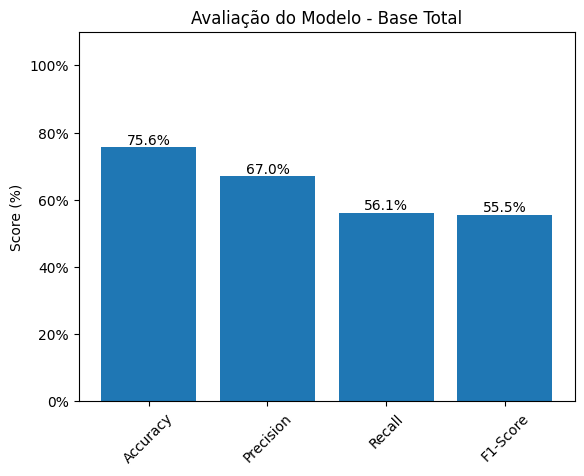

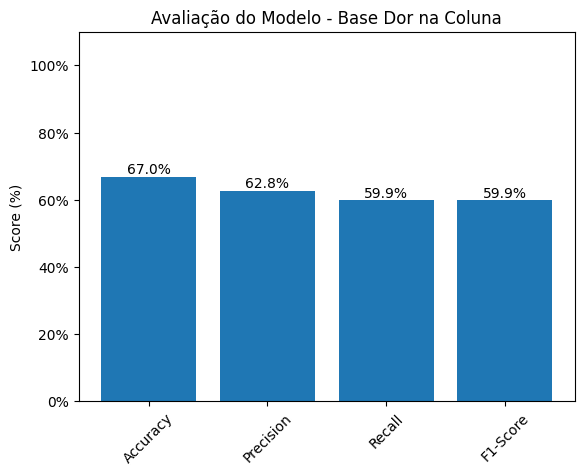

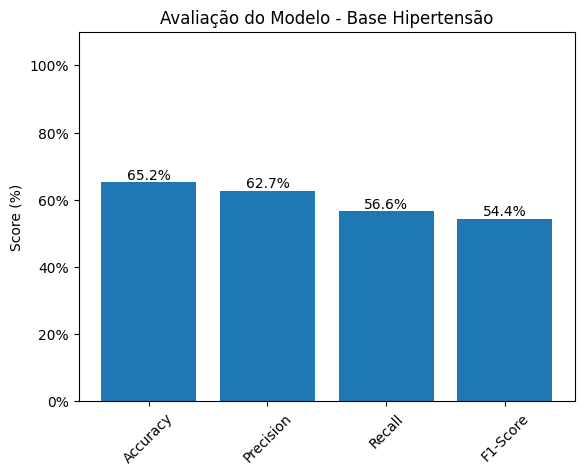

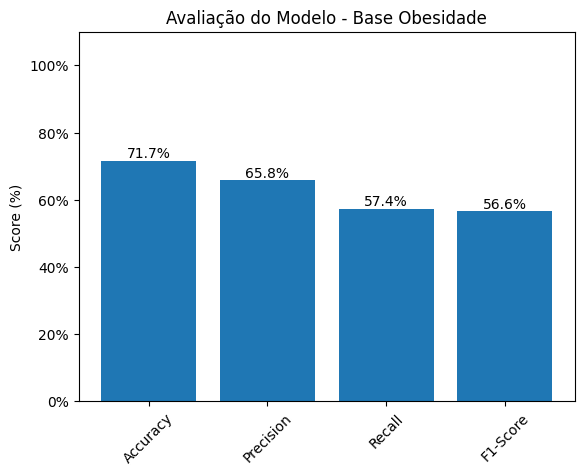

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
metrics_total_73 = metrics_total_72.copy()
metrics_coluna_73 = metrics_coluna_72.copy()
metrics_hipertensao_73 = metrics_hipertensao_72.copy()
metrics_obesidade_73 = metrics_obesidade_72.copy()

# Chame a função para plotar as métricas de ambos os conjuntos
plotar_metricas(metrics_total_73, "Base Total")
plotar_metricas(metrics_coluna_73, "Base Dor na Coluna")
plotar_metricas(metrics_hipertensao_73, "Base Hipertensão")
plotar_metricas(metrics_obesidade_73, "Base Obesidade")

### **7.4 - Importância das Features**

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
best_model_total_74 = best_model_total_72
x_total_74 = x_total_71.copy()
y_total_74 = y_total_71.copy()

best_model_coluna_74 = best_model_coluna_72
x_coluna_74 = x_coluna_71.copy()
y_coluna_74 = y_coluna_71.copy()

best_model_hipertensao_74 = best_model_hipertensao_72
x_hipertensao_74 = x_hipertensao_71.copy()
y_hipertensao_74 = y_hipertensao_71.copy()

best_model_obesidade_74 = best_model_obesidade_72
x_obesidade_74 = x_obesidade_71.copy()
y_obesidade_74 = y_obesidade_71.copy()

# Chame a função para plotar a importância das features
# plotar_importancia_features(best_model_total_74, x_total_74, y_total_74, "Base Total")
# plotar_importancia_features(best_model_coluna_74, x_coluna_74, y_coluna_74, "Base Dor na Coluna")
# plotar_importancia_features(best_model_hipertensao_74, x_hipertensao_74, y_hipertensao_74, "Base Hipertensão")
# plotar_importancia_features(best_model_obesidade_74, x_obesidade_74, y_obesidade_74, "Base Obesidade")

### **7.5 - Matriz de Confusão**

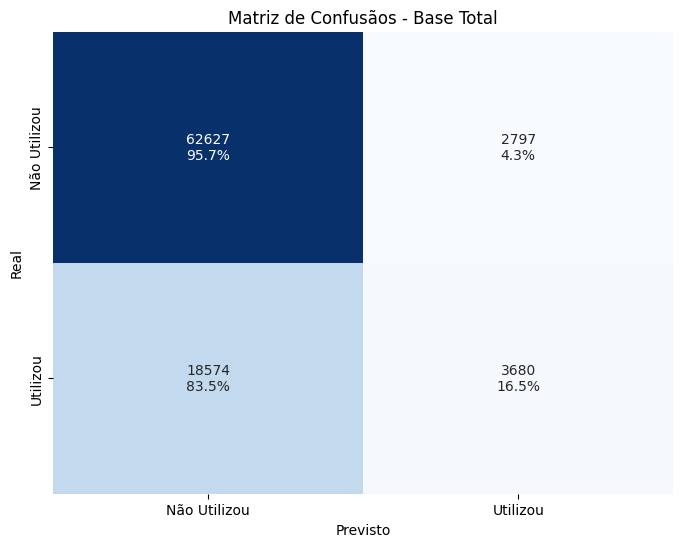

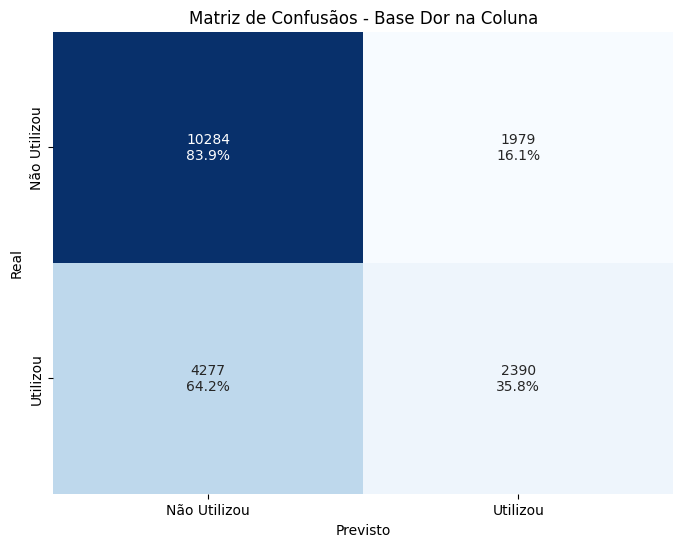

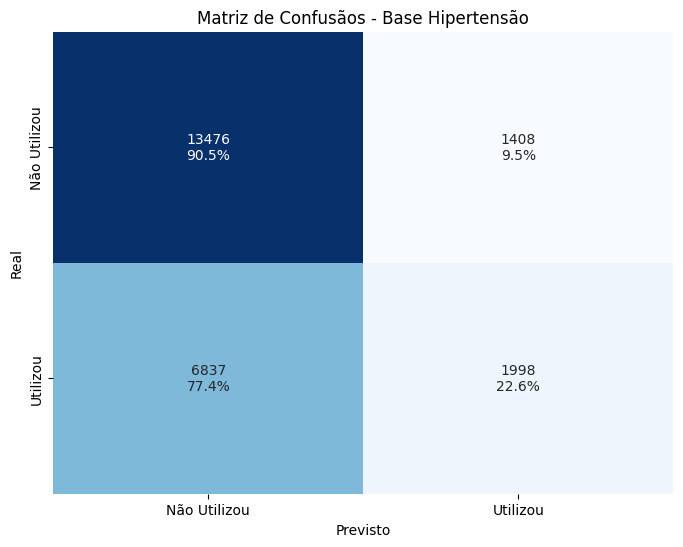

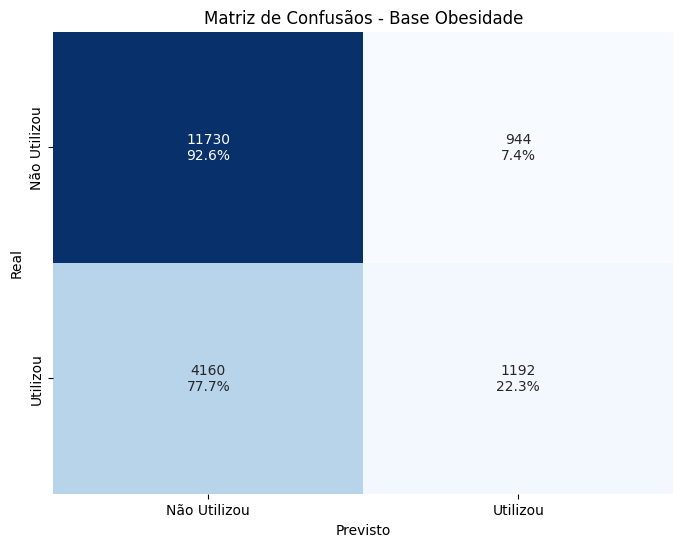

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
matrices_total_75 = matrices_total_72.copy()
matrices_coluna_75 = matrices_coluna_72.copy()
matrices_hipertensao_75 = matrices_hipertensao_72.copy()
matrices_obesidade_75 = matrices_obesidade_72.copy()

# Chame a função para plotar a importância das features
plotar_matriz_confusao(matrices_total_75, "Base Total")
plotar_matriz_confusao(matrices_coluna_75, "Base Dor na Coluna")
plotar_matriz_confusao(matrices_hipertensao_75, "Base Hipertensão")
plotar_matriz_confusao(matrices_obesidade_75, "Base Obesidade")

### **7.6 - Avaliação do Resultado**

**Acurácia (Accuracy): 00.00%** \\
Uma acurácia de...

**Precisão (Precision): 00.00%** \\
Uma precisão de...

**Recall (Recall): 00.00%** \\
Um recall de...

**F1-Score: 00.00%** \\
Um F1-score de...

**Interpretação Geral** \\
A análise dessas métricas...

## **Etapa 8 - Classificação com XGBoost**

Nesta etapa, empregamos o classificador XGBoost (eXtreme Gradient Boosting), um algoritmo de aprendizado de máquina poderoso e eficiente baseado em árvores de decisão. Ele constrói um conjunto de árvores de decisão de forma sequencial, onde cada nova árvore tenta corrigir os erros das árvores anteriores, resultando em um modelo altamente preciso. O XGBoost é conhecido por sua capacidade de lidar com dados de alta dimensionalidade, dados esparsos e lidar com problemas complexos de classificação. A otimização de hiperparâmetros, como a taxa de aprendizado, a profundidade máxima das árvores e o número de estimadores, é fundamental para alcançar um bom desempenho com o XGBoost, equilibrando o poder preditivo com a capacidade de generalização do modelo.

### **8.1 - Aplicando o Modelo**

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
x_total_81 = x_total.copy()
y_total_81 = y_total.copy()
weights_total_81 = weights_total.copy()
x_clustered_total_81 = x_clustered_total.copy()

x_coluna_81 = x_coluna.copy()
y_coluna_81 = y_coluna.copy()
weights_coluna_81 = weights_coluna.copy()
x_clustered_coluna_81 = x_clustered_coluna.copy()

x_hipertensao_81 = x_hipertensao.copy()
y_hipertensao_81 = y_hipertensao.copy()
weights_hipertensao_81 = weights_hipertensao.copy()
x_clustered_hipertensao_81 = x_clustered_hipertensao.copy()

x_obesidade_81 = x_obesidade.copy()
y_obesidade_81 = y_obesidade.copy()
weights_obesidade_81 = weights_obesidade.copy()
x_clustered_obesidade_81 = x_clustered_obesidade.copy()

# Define o modelo XGBoost
clf_classificador_81 = XGBClassifier(random_state=42, eval_metric='logloss')


# Define o número de folds para a validação cruzada
n_splits = 5

# Define a grade de hiperparâmetros para o XGBoost
param_grid = {
    'n_estimators': [50, 100],      # Número de árvores de decisão
    'max_depth': [3, 5],            # Profundidade máxima de cada árvore
    'learning_rate': [0.01, 0.1],   # Taxa de aprendizado (step size shrinkage)
    'subsample': [0.8, 1.0],        # Subamostragem de linhas (porcentagem de amostras usadas em cada árvore)
    'colsample_bytree': [0.8, 1.0], # Subamostragem de colunas (porcentagem de features usadas em cada árvore)
    'gamma': [0, 0.1, 0.5],         # Valor mínimo de redução de perda necessário para fazer uma nova partição em uma folha
    'reg_alpha': [0, 0.1, 1],       # Termo de regularização L1 em ​​pesos
    'reg_lambda': [0, 0.1, 1]       # Termo de regularização L2 em ​​pesos
}

# Chama a função para treinar 0 modelo
metrics_total_81, matrices_total_81, best_model_total_81 = treinar_modelo(
    x_total_81,
    y_total_81,
    weights_total_81,
    clf_classificador_81,
    n_splits,
    param_grid,
    "Base Total"
)
salvar_resultados_modelo(metrics_total_81, matrices_total_81, best_model_total_81, "XGBoost/BaseTotal")

metrics_coluna_81, matrices_coluna_81, best_model_coluna_81 = treinar_modelo(
    x_coluna_81,
    y_coluna_81,
    weights_coluna_81,
    clf_classificador_81,
    n_splits,
    param_grid,
    "Base Dor na Coluna"
)
salvar_resultados_modelo(metrics_coluna_81, matrices_coluna_81, best_model_coluna_81, "XGBoost/BaseColuna")

metrics_hipertensao_81, matrices_hipertensao_81, best_model_hipertensao_81 = treinar_modelo(
    x_hipertensao_81,
    y_hipertensao_81,
    weights_hipertensao_81,
    clf_classificador_81,
    n_splits,
    param_grid,
    "Base Hipertensão"
)
salvar_resultados_modelo(metrics_hipertensao_81, matrices_hipertensao_81, best_model_hipertensao_81, "XGBoost/BaseHipertensao")

metrics_obesidade_81, matrices_obesidade_81, best_model_obesidade_81 = treinar_modelo(
    x_obesidade_81,
    y_obesidade_81,
    weights_obesidade_81,
    clf_classificador_81,
    n_splits,
    param_grid,
    "Base Obesidade"
)
salvar_resultados_modelo(metrics_obesidade_81, matrices_obesidade_81, best_model_obesidade_81, "XGBoost/BaseObesidade")

Validação Cruzada - Base Total:   0%|          | 0/5 [00:00<?, ?it/s]

Fitting 5 folds for each of 864 candidates, totalling 4320 fits


Validação Cruzada - Base Total:  20%|██        | 1/5 [15:34<1:02:16, 934.13s/it]

Fitting 5 folds for each of 864 candidates, totalling 4320 fits


Validação Cruzada - Base Total:  40%|████      | 2/5 [30:02<44:46, 895.53s/it]  

Fitting 5 folds for each of 864 candidates, totalling 4320 fits


... (10 outputs left out)

Validação Cruzada - Base Dor na Coluna:  60%|██████    | 3/5 [23:38<15:44, 472.31s/it]

Fitting 5 folds for each of 864 candidates, totalling 4320 fits


Validação Cruzada - Base Dor na Coluna:  80%|████████  | 4/5 [31:38<07:55, 475.58s/it]

Fitting 5 folds for each of 864 candidates, totalling 4320 fits


### **8.2 - Declara Resultados do Modelo**

In [ ]:
# Carrega os resultados da pasta "Pasta/PastaInterna"
metrics_total_82, matrices_total_82, best_model_total_82, = carregar_resultados_modelo("XGBoost/BaseTotal")
metrics_coluna_82, matrices_coluna_82, best_model_coluna_82, = carregar_resultados_modelo("XGBoost/BaseColuna")
metrics_hipertensao_82, matrices_hipertensao_82, best_model_hipertensao_82, = carregar_resultados_modelo("XGBoost/BaseHipertensao")
metrics_obesidade_82, matrices_obesidade_82, best_model_obesidade_82, = carregar_resultados_modelo("XGBoost/BaseObesidade")

### **8.3 - Visualização das Métricas**

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
metrics_total_83 = metrics_total_82.copy()
metrics_coluna_83 = metrics_coluna_82.copy()
metrics_hipertensao_83 = metrics_hipertensao_82.copy()
metrics_obesidade_83 = metrics_obesidade_82.copy()

# Chame a função para plotar as métricas de ambos os conjuntos
plotar_metricas(metrics_total_83, "Base Total")
plotar_metricas(metrics_coluna_83, "Base Dor na Coluna")
plotar_metricas(metrics_hipertensao_83, "Base Hipertensão")
plotar_metricas(metrics_obesidade_83, "Base Obesidade")

### **8.4 - Importância das Features**

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
best_model_total_84 = best_model_total_82
x_total_84 = x_total_81.copy()
y_total_84 = y_total_81.copy()

best_model_coluna_84 = best_model_coluna_82
x_coluna_84 = x_coluna_81.copy()
y_coluna_84 = y_coluna_81.copy()

best_model_hipertensao_84 = best_model_hipertensao_82
x_hipertensao_84 = x_hipertensao_81.copy()
y_hipertensao_84 = y_hipertensao_81.copy()

best_model_obesidade_84 = best_model_obesidade_82
x_obesidade_84 = x_obesidade_81.copy()
y_obesidade_84 = y_obesidade_81.copy()

# Chame a função para plotar a importância das features
plotar_importancia_features(best_model_total_84, x_total_84, y_total_84, "Base Total")
plotar_importancia_features(best_model_coluna_84, x_coluna_84, y_coluna_84, "Base Dor na Coluna")
plotar_importancia_features(best_model_hipertensao_84, x_hipertensao_84, y_hipertensao_84, "Base Hipertensão")
plotar_importancia_features(best_model_obesidade_84, x_obesidade_84, y_obesidade_84, "Base Obesidade")

### **8.5 - Matriz de Confusão**

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
matrices_total_85 = matrices_total_82.copy()
matrices_coluna_85 = matrices_coluna_82.copy()
matrices_hipertensao_85 = matrices_hipertensao_82.copy()
matrices_obesidade_85 = matrices_obesidade_82.copy()

# Chame a função para plotar a importância das features
plotar_matriz_confusao(matrices_total_85, "Base Total")
plotar_matriz_confusao(matrices_coluna_85, "Base Dor na Coluna")
plotar_matriz_confusao(matrices_hipertensao_85, "Base Hipertensão")
plotar_matriz_confusao(matrices_obesidade_85, "Base Obesidade")

### **8.6 - Avaliação do Resultado**

**Acurácia (Accuracy): 00.00%** \\
Uma acurácia de...

**Precisão (Precision): 00.00%** \\
Uma precisão de...

**Recall (Recall): 00.00%** \\
Um recall de...

**F1-Score: 00.00%** \\
Um F1-score de...

**Interpretação Geral** \\
A análise dessas métricas...

## **Etapa 6 - Classificação com SVC (Support Vector Classifier)**

Nesta etapa, utilizamos o classificador SVC (Support Vector Classifier), que busca encontrar o melhor hiperplano que separa as diferentes classes de dados com a maior margem possível. Em outras palavras, ele tenta criar uma fronteira clara entre os grupos, maximizando a distância entre os pontos de dados mais próximos de cada classe. O SVC é particularmente eficaz em situações onde os dados não são linearmente separáveis, permitindo o uso de diferentes funções kernel para mapear os dados em um espaço de maior dimensão, onde a separação linear se torna possível.

### **6.1 - Aplicando o Modelo**

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
x_total_61 = x_total.copy()
y_total_61 = y_total.copy()
weights_total_61 = weights_total.copy()
x_clustered_total_61 = x_clustered_total.copy()

x_coluna_61 = x_coluna.copy()
y_coluna_61 = y_coluna.copy()
weights_coluna_61 = weights_coluna.copy()
x_clustered_coluna_61 = x_clustered_coluna.copy()

x_hipertensao_61 = x_hipertensao.copy()
y_hipertensao_61 = y_hipertensao.copy()
weights_hipertensao_61 = weights_hipertensao.copy()
x_clustered_hipertensao_61 = x_clustered_hipertensao.copy()

x_obesidade_61 = x_obesidade.copy()
y_obesidade_61 = y_obesidade.copy()
weights_obesidade_61 = weights_obesidade.copy()
x_clustered_obesidade_61 = x_clustered_obesidade.copy()

# Define o modelo SVC
clf_classificador_61 = SVC(random_state=42)

# Define o número de folds para a validação cruzada
n_splits = 5

# Define a grade de hiperparâmetros para o SVC
param_grid = {
    'C': [0.1, 1, 10],          # Parâmetro de regularização
    'kernel': ['poly', 'rbf'],  # Tipo de kernel
    'gamma': ['scale', 'auto'], # Coeficiente do kernel para 'rbf' e 'poly'
    'degree': [2, 3, 4]         # Testa diferentes graus para o kernel polinomial
}

# Chama a função para treinar o modelo e salvar os resultados
metrics_total_61, matrices_total_61, best_model_total_61 = treinar_modelo(
    x_total_61,
    y_total_61,
    weights_total_61,
    clf_classificador_61,
    n_splits,
    param_grid,
    "Base Total"
)
salvar_resultados_modelo(metrics_total_61, matrices_total_61, best_model_total_61, "SVC/BaseTotal")


metrics_coluna_61, matrices_coluna_61, best_model_coluna_61 = treinar_modelo(
    x_coluna_61,
    y_coluna_61,
    weights_coluna_61,
    clf_classificador_61,
    n_splits,
    param_grid,
    "Base Dor na Coluna"
)
salvar_resultados_modelo(metrics_coluna_61, matrices_coluna_61, best_model_coluna_61, "SVC/BaseColuna")


metrics_hipertensao_61, matrices_hipertensao_61, best_model_hipertensao_61 = treinar_modelo(
    x_hipertensao_61,
    y_hipertensao_61,
    weights_hipertensao_61,
    clf_classificador_61,
    n_splits,
    param_grid,
    "Base Hipertensão"
)
salvar_resultados_modelo(metrics_hipertensao_61, matrices_hipertensao_61, best_model_hipertensao_61, "SVC/BaseHipertensao")


metrics_obesidade_61, matrices_obesidade_61, best_model_obesidade_61 = treinar_modelo(
    x_obesidade_61,
    y_obesidade_61,
    weights_obesidade_61,
    clf_classificador_61,
    n_splits,
    param_grid,
    "Base Obesidade"
)
salvar_resultados_modelo(metrics_obesidade_61, matrices_obesidade_61, best_model_obesidade_61, "SVC/BaseObesidade")

Validação Cruzada - Base Total:   0%|          | 0/5 [00:00<?, ?it/s]

Fitting 5 folds for each of 1 candidates, totalling 5 fits


Validação Cruzada - Base Total:  20%|██        | 1/5 [03:52<15:31, 232.81s/it]

Fitting 5 folds for each of 1 candidates, totalling 5 fits


Validação Cruzada - Base Total:  40%|████      | 2/5 [07:48<11:43, 234.60s/it]

Fitting 5 folds for each of 1 candidates, totalling 5 fits


... (31 outputs left out)

Fitting 5 folds for each of 1 candidates, totalling 5 fits


Validação Cruzada - Base Obesidade:  80%|████████  | 4/5 [00:44<00:11, 11.10s/it]

Fitting 5 folds for each of 1 candidates, totalling 5 fits


Validação Cruzada - Base Obesidade: 100%|██████████| 5/5 [00:54<00:00, 10.88s/it]


### **6.2 - Declara Resultados do Modelo**

In [ ]:
# Carrega os resultados da pasta "Pasta/PastaInterna"
metrics_total_62, matrices_total_62, best_model_total_62, = carregar_resultados_modelo("SVC/BaseTotal")
metrics_coluna_62, matrices_coluna_62, best_model_coluna_62, = carregar_resultados_modelo("SVC/BaseColuna")
metrics_hipertensao_62, matrices_hipertensao_62, best_model_hipertensao_62, = carregar_resultados_modelo("SVC/BaseHipertensao")
metrics_obesidade_62, matrices_obesidade_62, best_model_obesidade_62, = carregar_resultados_modelo("SVC/BaseObesidade")

### **6.3 - Visualização das Métricas**

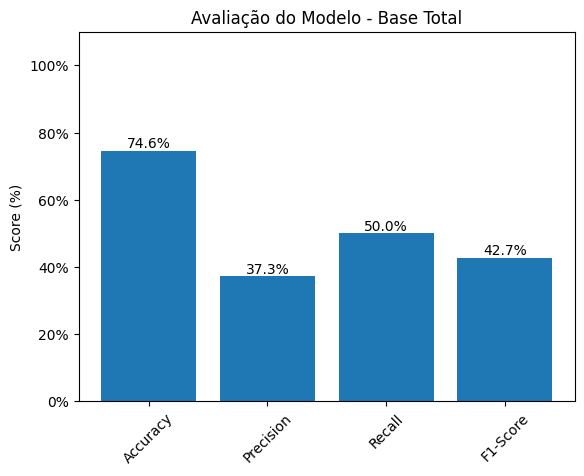

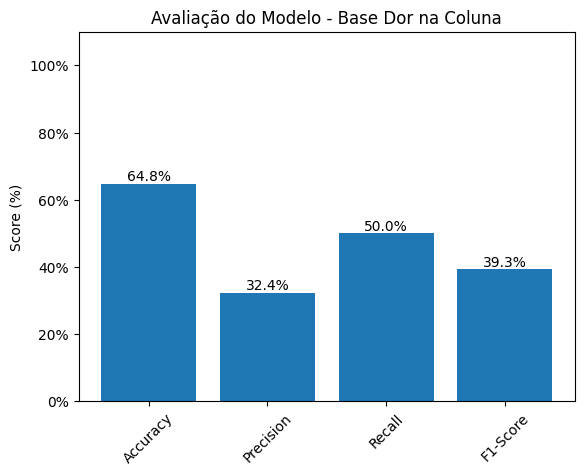

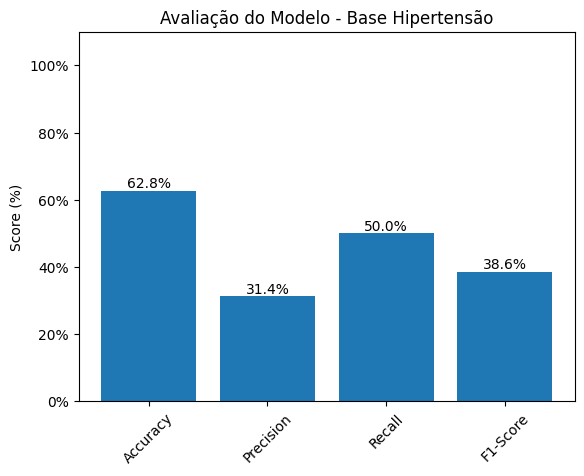

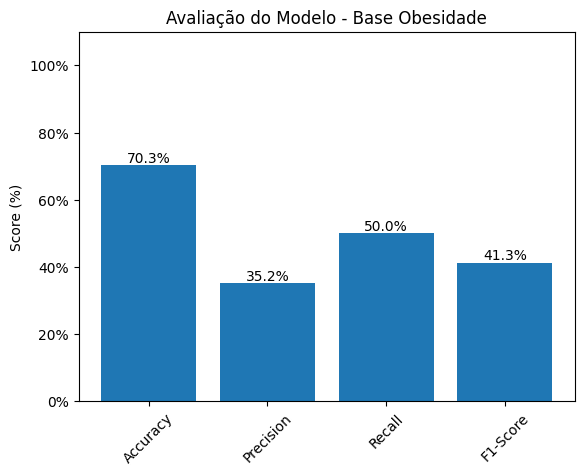

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
metrics_total_63 = metrics_total_62.copy()
metrics_coluna_63 = metrics_coluna_62.copy()
metrics_hipertensao_63 = metrics_hipertensao_62.copy()
metrics_obesidade_63 = metrics_obesidade_62.copy()

# Chame a função para plotar as métricas de ambos os conjuntos
plotar_metricas(metrics_total_63, "Base Total")
plotar_metricas(metrics_coluna_63, "Base Dor na Coluna")
plotar_metricas(metrics_hipertensao_63, "Base Hipertensão")
plotar_metricas(metrics_obesidade_63, "Base Obesidade")

### **6.4 - Importância das Features**

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
best_model_total_64 = best_model_total_62
x_total_64 = x_total_61.copy()
y_total_64 = y_total_61.copy()

best_model_coluna_64 = best_model_coluna_62
x_coluna_64 = x_coluna_61.copy()
y_coluna_64 = y_coluna_61.copy()

best_model_hipertensao_64 = best_model_hipertensao_62
x_hipertensao_64 = x_hipertensao_61.copy()
y_hipertensao_64 = y_hipertensao_61.copy()

best_model_obesidade_64 = best_model_obesidade_62
x_obesidade_64 = x_obesidade_61.copy()
y_obesidade_64 = y_obesidade_61.copy()

# Chame a função para plotar a importância das features
# plotar_importancia_features(best_model_total_64, x_total_64, y_total_64, "Base Total")
# plotar_importancia_features(best_model_coluna_64, x_coluna_64, y_coluna_64, "Base Dor na Coluna")
# plotar_importancia_features(best_model_hipertensao_64, x_hipertensao_64, y_hipertensao_64, "Base Hipertensão")
# plotar_importancia_features(best_model_obesidade_64, x_obesidade_64, y_obesidade_64, "Base Obesidade")

### **6.5 - Matriz de Confusão**

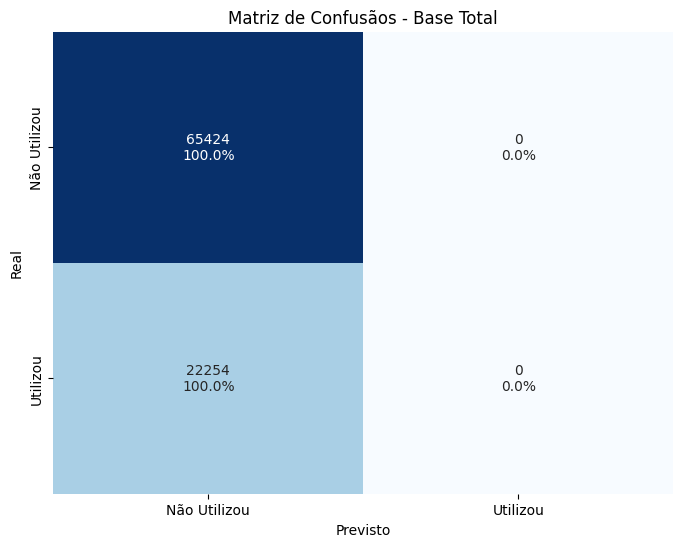

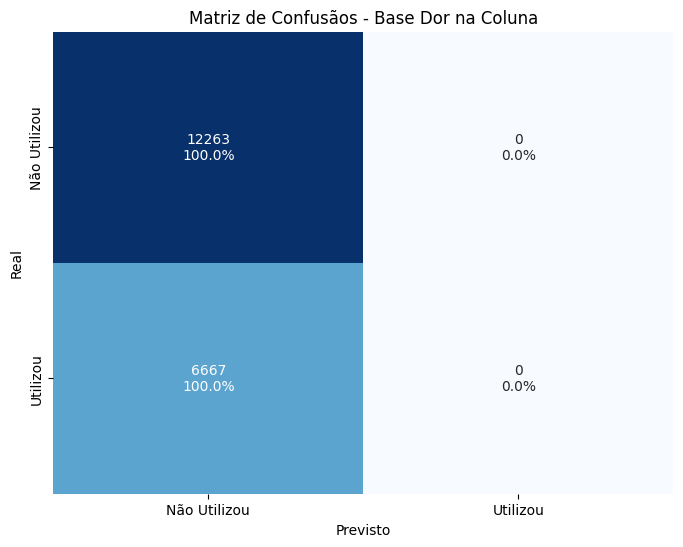

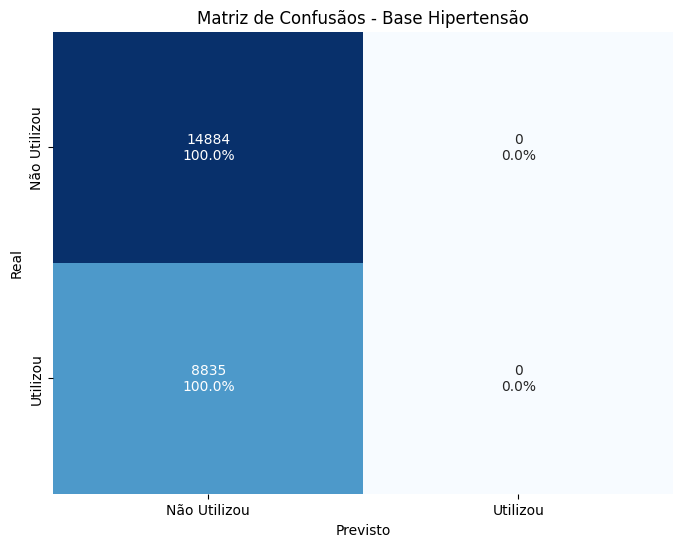

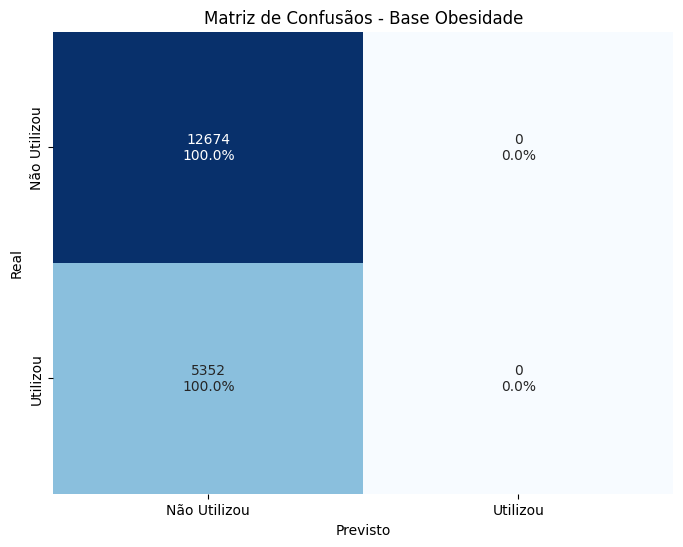

In [ ]:
# Cria cópias das variáveis originais para evitar modificações indesejadas
matrices_total_65 = matrices_total_62.copy()
matrices_coluna_65 = matrices_coluna_62.copy()
matrices_hipertensao_65 = matrices_hipertensao_62.copy()
matrices_obesidade_65 = matrices_obesidade_62.copy()

# Chame a função para plotar a importância das features
plotar_matriz_confusao(matrices_total_65, "Base Total")
plotar_matriz_confusao(matrices_coluna_65, "Base Dor na Coluna")
plotar_matriz_confusao(matrices_hipertensao_65, "Base Hipertensão")
plotar_matriz_confusao(matrices_obesidade_65, "Base Obesidade")

### **6.6 - Avaliação do Resultado**

**Acurácia (Accuracy): 00.00%** \\
Uma acurácia de...

**Precisão (Precision): 00.00%** \\
Uma precisão de...

**Recall (Recall): 00.00%** \\
Um recall de...

**F1-Score: 00.00%** \\
Um F1-score de...

**Interpretação Geral** \\
A análise dessas métricas...